# 📉 Customer Churn Prediction — A Binary Classification Tutorial

> **Goal:** predict which customers of a telecom company are about to leave (*churn*), so that the company can try to keep them, for example by offering a discount or a gift.

This notebook walks through a complete machine-learning project, step by step:

| # | Section | What you will learn |
|---|---------|---------------------|
| 1 | [Setup](#1.-Setup) | Libraries and plotting style |
| 2 | [Getting the data](#2.-Getting-the-data) | Downloading the Telco dataset |
| 3 | [First look at the data](#3.-First-look-at-the-data) | Columns, data types, data dictionary |
| 4 | [Data cleaning](#4.-Data-cleaning) | Fixing wrong types, missing values, encoding the target |
| 5 | [Train / validation / test split](#5.-Train-/-validation-/-test-split) | Why we need three sets, and how to make a 60/20/20 split |
| 6 | [Exploratory data analysis](#6.-Exploratory-Data-Analysis-(EDA)) | Churn rate, difference and risk ratio |
| 7 | [Mutual information](#7.-Feature-importance-for-categorical-features:-Mutual-Information) | Importance of categorical features (with math) |
| 8 | [Correlation](#8.-Feature-importance-for-numerical-features:-Correlation) | Importance of numerical features (with math) |
| 9 | [One-hot encoding](#9.-One-hot-encoding) | `DictVectorizer` vs `OneHotEncoder` |
| 10 | [Logistic regression](#10.-Logistic-Regression) | Theory, training, and interpreting the weights |
| 11 | [Evaluating the classifier](#11.-Evaluating-the-classifier) | Confusion matrix, precision, recall, ROC/AUC, threshold |
| 12 | [Using the model](#12.-Using-the-model) | Final training, testing, and scoring single customers |
| 13 | [The Perceptron](#13.-The-Perceptron) | Implementing Rosenblatt's perceptron from scratch |
| 14 | [Final comparison](#14.-Final-comparison-and-conclusions) | Which model wins, and what to try next |

**The question we want to answer:**

$$\text{Given what we know about a customer } \mathbf{x}, \text{ what is } P(\text{churn} = 1 \mid \mathbf{x})\text{?}$$

This is a **binary classification** problem: the target $y$ only takes two values, $y \in \{0, 1\}$ (`0` = stays, `1` = churns).

## 1. Setup

We use the classic Python data-science stack:

- **NumPy** for numerical computing,
- **pandas** for tabular data,
- **Matplotlib** for plots,
- **scikit-learn** for machine learning.

The cell below also defines a small, consistent color palette. Throughout the notebook, **blue means "stays"** (`Churn = 0`) and **orange means "churns"** (`Churn = 1`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

SEED = 1  # one seed for every random operation -> reproducible results

# ---------------------------------------------------------------------------
# Plot style
# ---------------------------------------------------------------------------
STAY = "#2a78d6"   # blue   -> customers who stay  (Churn = 0)
CHURN = "#eb6834"  # orange -> customers who churn (Churn = 1)
THIRD = "#1baf7a"  # aqua   -> a third series, when one is needed

# Signed quantities ("lowers churn" vs "raises churn") use a blue <-> red scale
LOWER, RAISE, MIDDLE = "#2a78d6", "#e34948", "#f0efec"

INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#8a8984"  # text colors
GRID, SURFACE = "#e6e5e1", "#fcfcfb"

BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list("diverging", [LOWER, MIDDLE, RAISE])

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": INK_3,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 10,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "legend.fontsize": 9,
    "font.size": 10,
})

pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 4)

## 2. Getting the data

We use the **[Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)** dataset, originally published by IBM as a sample dataset. Each row is one customer, and the `Churn` column tells us whether that customer left the company during the last month.

A copy of the CSV file is already in the `data/` folder. If you want to download it yourself, uncomment the next cell. It uses [`kagglehub`](https://github.com/Kaggle/kagglehub) (`pip install kagglehub`).

In [2]:
# import kagglehub
#
# # Download the latest version of the dataset
# path = kagglehub.dataset_download("blastchar/telco-customer-churn")
# print("Path to dataset files:", path)
#
# # Then copy "WA_Fn-UseC_-Telco-Customer-Churn.csv" to data/churn_telco_data.csv

In [3]:
df = pd.read_csv("data/churn_telco_data.csv")

print(f"{df.shape[0]:,} customers (rows) and {df.shape[1]} columns")
df.head()

7,043 customers (rows) and 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. First look at the data

Before building any model, we should understand what each column means.

| Group | Column | Meaning |
|-------|--------|---------|
| **ID** | `customerID` | Unique customer identifier (not a useful feature) |
| **Demographics** | `gender` | `Male` / `Female` |
| | `SeniorCitizen` | `1` if the customer is 65 or older, else `0` |
| | `Partner` | Does the customer have a partner? |
| | `Dependents` | Does the customer have dependents (children, parents, …)? |
| **Account** | `tenure` | Number of months the customer has stayed with the company |
| | `Contract` | `Month-to-month`, `One year`, `Two year` |
| | `PaperlessBilling` | Does the customer receive bills electronically? |
| | `PaymentMethod` | Electronic check, mailed check, bank transfer, credit card |
| | `MonthlyCharges` | Amount charged every month |
| | `TotalCharges` | Total amount charged so far |
| **Services** | `PhoneService`, `MultipleLines` | Phone services |
| | `InternetService` | `DSL`, `Fiber optic`, `No` |
| | `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport` | Internet add-ons |
| | `StreamingTV`, `StreamingMovies` | Streaming add-ons |
| **Target** | `Churn` | Did the customer leave? `Yes` / `No` |

In [4]:
# All column names
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


Now let's check the data type of each column.

> ⚠️ **Note:** the data type in pandas is not always the *meaning* of a column.
> - `SeniorCitizen` is stored as an integer, but it is really **categorical** (only `0` or `1`).
> - `TotalCharges` should be a number, but it is stored as a **string**. We will fix this in the next section.

In [5]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

## 4. Data cleaning

### 4.1 Fixing `TotalCharges`

`TotalCharges` is stored as text because some of its values are not numbers. We convert the column with `pd.to_numeric(..., errors="coerce")`: every value that cannot be parsed becomes `NaN` (*Not a Number*), so we can easily find it.

In [6]:
total_charges = pd.to_numeric(df.TotalCharges, errors="coerce")

# Which rows could not be converted, and what did they contain?
bad_rows = df[total_charges.isna()]
print("Original values that failed to parse:", bad_rows.TotalCharges.unique().tolist())

bad_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Original values that failed to parse: [' ']


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


The broken values are blank strings `" "`. Look at the `tenure` column: **all of these customers have `tenure = 0`**. They have just signed up and have not been billed yet, so their total charge really is $0$.

This means that filling the missing values with `0` is not only a quick fix. It is the **correct** value for these customers.

> 💡 **In general**, there are several strategies for missing values: drop the rows, fill with `0`, the mean or median, or predict the value with another model. The right choice depends on *why* the value is missing. Always look at the rows before deciding.

In [7]:
df.TotalCharges = total_charges.fillna(0)

# Count missing values in every column -> everything should be 0 now
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

### 4.2 Encoding the target

Machine-learning models work with numbers, not with the strings `"Yes"` and `"No"`. We encode the target as:

$$
y = \begin{cases} 1 & \text{if Churn} = \text{"Yes"} \\ 0 & \text{if Churn} = \text{"No"} \end{cases}
$$

Using `1` for the class we care about (the **positive class**, churn) has a nice benefit. The **mean** of the column is then exactly the **churn rate**, as we will see in Section 6.

In [8]:
print("Before:", df.Churn.unique().tolist())

# (df.Churn == "Yes") is a boolean Series; .astype(int) maps True -> 1, False -> 0
df.Churn = (df.Churn == "Yes").astype(int)

print("After: ", df.Churn.unique().tolist())

Before: ['No', 'Yes']
After:  [0, 1]


In [9]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

## 5. Train / validation / test split

We split the data into three parts, each with its own role:

| Set | Share | Role |
|-----|-------|------|
| **Train** | 60 % | The model **learns** its parameters from this data. |
| **Validation** | 20 % | We **compare** models and tune settings (e.g. the decision threshold). |
| **Test** | 20 % | Used **only once at the end** to estimate performance on new, unseen customers. |

If we tuned our choices on the test set, its score would become too optimistic. The test set has to stay a *surprise* for the model and for us.

### Why `test_size=0.25` in the second split?

`train_test_split` can only cut a dataset into **two** parts, so we call it twice:

1. First, keep 20 % aside as the test set. The remaining 80 % is `df_train_full`.
2. Then split `df_train_full` into train and validation. We want the validation set to be 20 % of the **whole** data, but we are now cutting only 80 % of it:

$$
\text{test\_size} = \frac{0.20}{0.80} = 0.25 \quad\Longrightarrow\quad
\underbrace{0.80 \times 0.75}_{\text{train}} = 0.60, \qquad
\underbrace{0.80 \times 0.25}_{\text{validation}} = 0.20
$$

In [10]:
from sklearn.model_selection import train_test_split

# Step 1: 80 % "full train" and 20 % test
df_train_full, df_test = train_test_split(df, test_size=0.20, random_state=SEED)

# Step 2: split the 80 % into 60 % train and 20 % validation (0.25 * 0.80 = 0.20)
df_train, df_valid = train_test_split(df_train_full, test_size=0.25, random_state=SEED)

assert len(df_train) + len(df_valid) + len(df_test) == len(df)

for name, part in [("train", df_train), ("validation", df_valid), ("test", df_test)]:
    print(f"{name:<11} {len(part):>5} rows  ({len(part) / len(df):.0%})"
          f"   churn rate = {part.Churn.mean():.3f}")

train        4225 rows  (60%)   churn rate = 0.269
validation   1409 rows  (20%)   churn rate = 0.274
test         1409 rows  (20%)   churn rate = 0.247


All three sets have a similar churn rate (about 25–27 %), so the random split is representative.

> 💡 For imbalanced data you can pass `stratify=df.Churn` to `train_test_split`. It then keeps the class ratio *exactly* the same in every part.

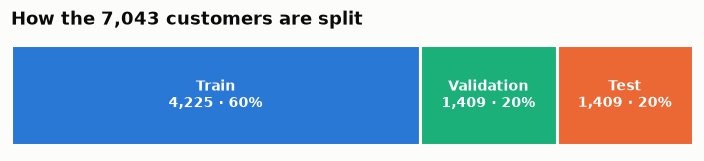

In [11]:
fig, ax = plt.subplots(figsize=(8, 1.3))
left = 0
for name, part, color in [("Train", df_train, STAY), ("Validation", df_valid, THIRD),
                          ("Test", df_test, CHURN)]:
    share = len(part) / len(df)
    ax.barh(0, share, left=left, color=color, edgecolor=SURFACE, linewidth=2)
    ax.text(left + share / 2, 0, f"{name}\n{len(part):,} · {share:.0%}",
            ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += share
ax.set_xlim(0, 1)
ax.axis("off")
ax.set_title("How the 7,043 customers are split")
plt.show()

Next we take the target out of the feature tables and store it in separate arrays `y_*`. Deleting the `Churn` column from the feature data frames makes sure we can **never use the answer as an input by accident**. That mistake is called *target leakage*.

`df_train_full` (train + validation) keeps its `Churn` column, because we use it for exploratory analysis and later to train the final model.

In [12]:
y_train = df_train.Churn.values
y_valid = df_valid.Churn.values
y_test = df_test.Churn.values

del df_train["Churn"]
del df_valid["Churn"]
del df_test["Churn"]

# Optional: after shuffling, the index is a random permutation. Resetting it is cleaner.
df_train_full = df_train_full.reset_index(drop=True)
df_train_full.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,5442-PPTJY,Male,0,Yes,Yes,12,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.70,258.35,0
1,6261-RCVNS,Female,0,No,No,42,Yes,No,DSL,Yes,Yes,Yes,Yes,No,Yes,One year,No,Credit card (automatic),73.90,3160.55,1
2,2176-OSJUV,Male,0,Yes,No,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,Two year,No,Bank transfer (automatic),65.15,4681.75,0
3,6161-ERDGD,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,No,Electronic check,85.45,6300.85,0
4,2364-UFROM,Male,0,No,No,30,Yes,No,DSL,Yes,Yes,No,Yes,Yes,No,One year,No,Electronic check,70.40,2044.75,0


## 6. Exploratory Data Analysis (EDA)

We now explore `df_train_full` (train + validation). We never look at the test set while exploring.

### 6.1 Missing values

In [13]:
# We already handled the missing values -> every count should be 0
df_train_full.isna().sum().sum()

np.int64(0)

### 6.2 The target: global churn rate

The **global churn rate** is the fraction of customers who churned:

$$
\text{churn rate} = \frac{\#\{\text{customers with } y_i = 1\}}{n}
$$

**Why is this the same as the mean of `Churn`?** Because $y_i \in \{0, 1\}$. When we add up the column, every churned customer adds $1$ and every other customer adds $0$, so the sum *counts* the churners:

$$
\bar{y} = \frac{1}{n}\sum_{i=1}^{n} y_i = \frac{\overbrace{1 + 1 + \dots + 1}^{\text{churners}} + \overbrace{0 + \dots + 0}^{\text{non-churners}}}{n} = \frac{\#\{y_i = 1\}}{n}
$$

That is why `value_counts(normalize=True)` and `.mean()` give the same number.

In [14]:
print(df_train_full.Churn.value_counts(normalize=True))

global_churn_rate = df_train_full.Churn.mean()
print(f"\nGlobal churn rate (mean of Churn): {global_churn_rate:.4f}")

Churn
0    0.73
1    0.27
Name: proportion, dtype: float64

Global churn rate (mean of Churn): 0.2700


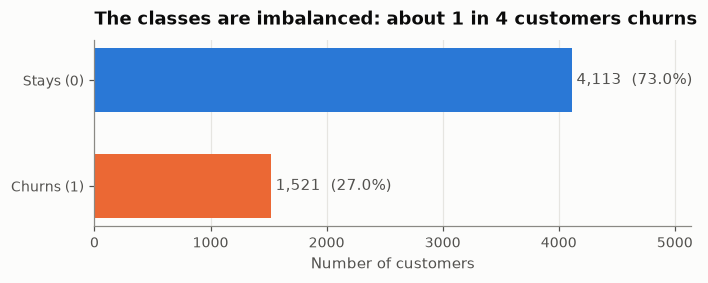

In [15]:
counts = df_train_full.Churn.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 2.2))
bars = ax.barh(["Stays (0)", "Churns (1)"], counts.values, color=[STAY, CHURN], height=0.6)
for bar, count in zip(bars, counts.values):
    ax.text(bar.get_width() + 40, bar.get_y() + bar.get_height() / 2,
            f"{count:,}  ({count / counts.sum():.1%})", va="center", color=INK_2)
ax.set_xlim(0, counts.max() * 1.25)
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
ax.set_xlabel("Number of customers")
ax.set_title("The classes are imbalanced: about 1 in 4 customers churns")
plt.show()

The dataset is **imbalanced**: about 73 % of customers stay. Keep this in mind. A "model" that always predicts *"stays"* would already be about **73 % accurate** without learning anything. Every real model has to beat this **baseline**.

### 6.3 Numerical vs. categorical features

Only three columns are truly numerical: `tenure`, `MonthlyCharges`, and `TotalCharges`. All other features are categorical. We drop `customerID` (an identifier says nothing about behavior) and `Churn` (it is the target, not a feature).

In [16]:
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]

all_features = [c for c in df.columns if c not in ("customerID", "Churn")]
# A list comprehension (instead of set difference) keeps the column order stable
categorical_features = [c for c in all_features if c not in numeric_features]

print(f"Numerical   ({len(numeric_features)}):", numeric_features)
print(f"Categorical ({len(categorical_features)}):", categorical_features)

Numerical   (3): ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical (16): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


A quick sanity check: a categorical feature should have only a **small number of unique values**. If one of them had hundreds of unique values, we would need to look at it again.

In [17]:
df_train_full[categorical_features].nunique()

gender              2
SeniorCitizen       2
Partner             2
Dependents          2
PhoneService        2
MultipleLines       3
InternetService     3
OnlineSecurity      3
OnlineBackup        3
DeviceProtection    3
TechSupport         3
StreamingTV         3
StreamingMovies     3
Contract            3
PaperlessBilling    2
PaymentMethod       4
dtype: int64

### 6.4 Numerical features: distributions by churn

Let's compare the distributions for customers who stay and customers who churn. We plot **densities** (each histogram has total area 1), because the two groups have very different sizes.

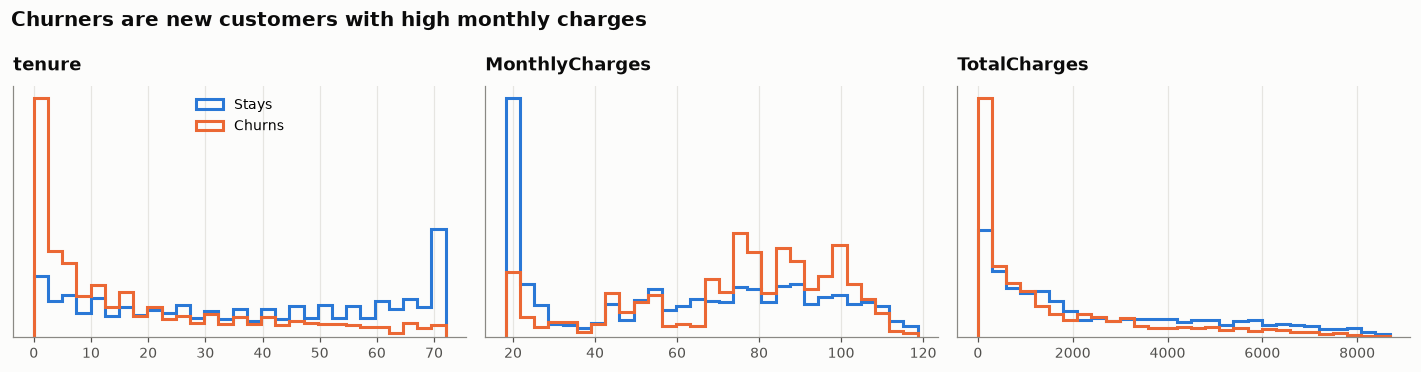

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, feature in zip(axes, numeric_features):
    bins = np.linspace(df_train_full[feature].min(), df_train_full[feature].max(), 30)
    for label, color, name in [(0, STAY, "Stays"), (1, CHURN, "Churns")]:
        values = df_train_full.loc[df_train_full.Churn == label, feature]
        ax.hist(values, bins=bins, density=True, histtype="step", linewidth=2,
                color=color, label=name)
    ax.set_title(feature)
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="upper center")
fig.suptitle("Churners are new customers with high monthly charges",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
plt.show()

**What we see:**
- **`tenure`**: churners are concentrated at very low tenure. Many customers leave during their first months.
- **`MonthlyCharges`**: churners pay more per month on average. Very cheap plans (≈ \$20) rarely churn.
- **`TotalCharges`**: churners have low totals. This is mostly a consequence of low tenure, because $\text{TotalCharges} \approx \text{tenure} \times \text{MonthlyCharges}$.

### 6.5 Categorical features: churn rate, difference, and risk ratio

For each category $g$ of a feature (e.g. `gender = Female`), we compute the **group churn rate** $p_g$. Then we compare it with the global rate $p$ in two ways.

**Difference:**

$$\text{diff}_g = p_g - p$$

- $\text{diff}_g > 0$: the group churns **more** than average.
- $\text{diff}_g < 0$: the group churns **less** than average.

**Risk ratio:**

$$\text{risk}_g = \frac{p_g}{p}$$

- $\text{risk}_g > 1$: the group is **more likely** to churn (e.g. $1.5$ means 50 % more likely than average).
- $\text{risk}_g < 1$: the group is **less likely** to churn.

The difference measures the gap in absolute *percentage points*. The risk ratio measures it in *relative* terms, which makes groups easier to compare when rates are small.

Let's start with `gender` and `Partner` by hand.

In [19]:
male_churn_rate = df_train_full[df_train_full.gender == "Male"].Churn.mean()
female_churn_rate = df_train_full[df_train_full.gender == "Female"].Churn.mean()
with_partner_churn_rate = df_train_full[df_train_full.Partner == "Yes"].Churn.mean()
no_partner_churn_rate = df_train_full[df_train_full.Partner == "No"].Churn.mean()

summary = pd.DataFrame({
    "churn rate": [male_churn_rate, female_churn_rate,
                   with_partner_churn_rate, no_partner_churn_rate],
}, index=["gender = Male", "gender = Female", "Partner = Yes", "Partner = No"])
summary["diff"] = summary["churn rate"] - global_churn_rate
summary["risk"] = summary["churn rate"] / global_churn_rate
summary

,churn rate,diff,risk
gender = Male,0.2632,-0.0068,0.9750
gender = Female,0.2768,0.0069,1.0254
Partner = Yes,0.2050,-0.0649,0.7595
Partner = No,0.3298,0.0598,1.2217


**Interpretation:**
- **Gender** barely matters. Men and women are within ≈ 0.7 percentage points of the global rate, and their risk ratios are ≈ 1.
- **Partner** matters a lot more. Customers *without* a partner are ≈ 22 % more likely to churn ($\text{risk} \approx 1.22$). Customers *with* a partner are ≈ 24 % less likely ($\text{risk} \approx 0.76$).

Doing this by hand for every feature is tedious. `groupby` + `agg` does it in one line:

In [20]:
df_gender = df_train_full.groupby("gender").Churn.agg(["mean", "count", "std"])
df_gender["diff"] = df_gender["mean"] - global_churn_rate
df_gender["risk"] = df_gender["mean"] / global_churn_rate
df_gender

,mean,count,std,diff,risk
gender,,,,,
Female,0.2768,2796,0.4475,0.0069,1.0254
Male,0.2632,2838,0.4405,-0.0068,0.9750


Let's do it for **all** categorical features at once. This would take us a lot of time by hand, but a computer needs only a few milliseconds.

In [21]:
def churn_stats(feature):
    """Churn rate, group size, difference and risk ratio for every category of `feature`."""
    stats = df_train_full.groupby(feature).Churn.agg(["mean", "count"])
    stats["diff"] = stats["mean"] - global_churn_rate
    stats["risk"] = stats["mean"] / global_churn_rate
    return stats


churn_analysis = {feature: churn_stats(feature) for feature in categorical_features}

for feature in ["Contract", "PaymentMethod", "InternetService"]:
    display(churn_analysis[feature])

,mean,count,diff,risk
Contract,,,,
Month-to-month,0.4317,3104,0.1617,1.5991
One year,0.1206,1186,-0.1494,0.4466
Two year,0.0283,1344,-0.2417,0.1047


,mean,count,diff,risk
PaymentMethod,,,,
Bank transfer (automatic),0.1682,1219,-0.1018,0.6229
Credit card (automatic),0.1643,1217,-0.1056,0.6087
Electronic check,0.4559,1893,0.1859,1.6887
Mailed check,0.1939,1305,-0.0761,0.7181


,mean,count,diff,risk
InternetService,,,,
DSL,0.1923,1934,-0.0776,0.7125
Fiber optic,0.4252,2479,0.1552,1.5749
No,0.0778,1221,-0.1922,0.2882


A picture is easier to read than 16 tables. In each panel below, a bar shows the churn rate of one category. The dashed line is the **global** churn rate. **Red** bars churn more than average ($\text{risk} > 1$), and **blue** bars churn less ($\text{risk} < 1$).

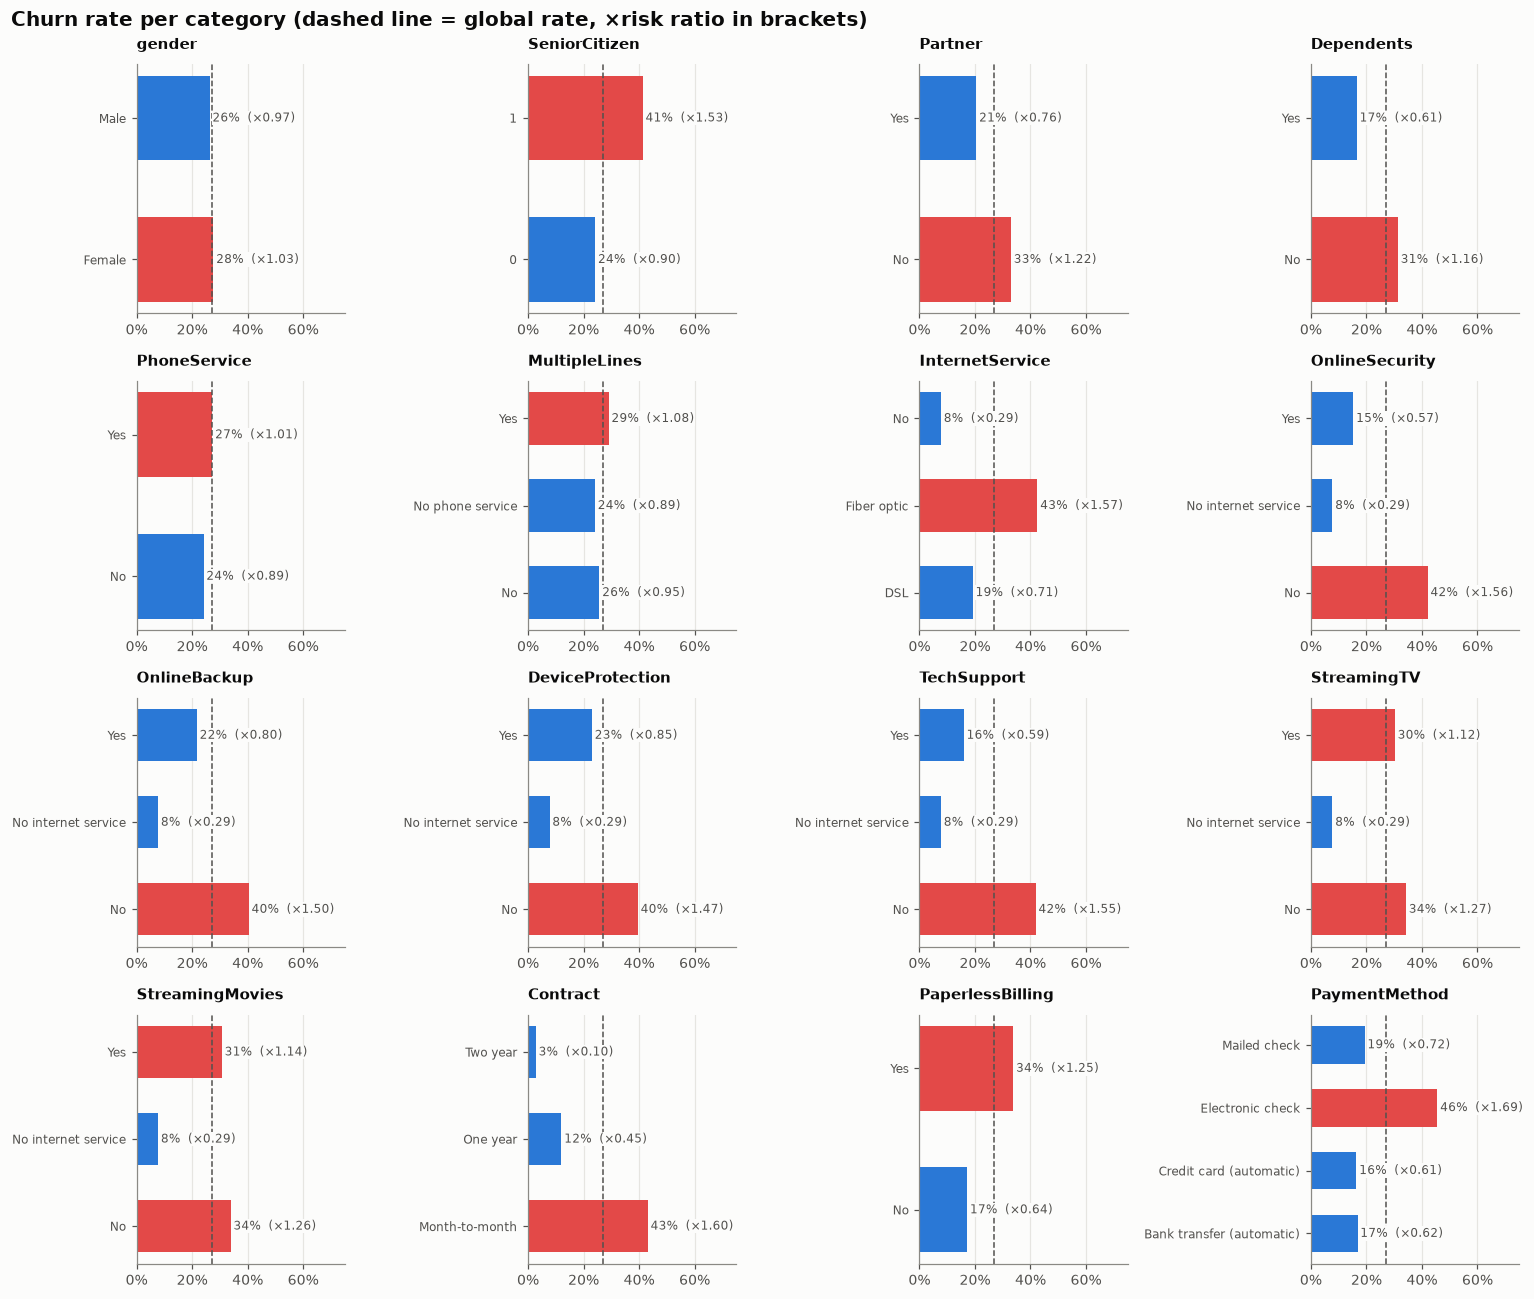

In [22]:
fig, axes = plt.subplots(4, 4, figsize=(14, 12))
for ax, feature in zip(axes.ravel(), categorical_features):
    stats = churn_analysis[feature]
    colors = [RAISE if r > 1 else LOWER for r in stats["risk"]]
    ax.barh(stats.index.astype(str), stats["mean"], color=colors, height=0.6)
    ax.axvline(global_churn_rate, color=INK_2, linestyle="--", linewidth=1)
    for y, (rate, risk) in enumerate(zip(stats["mean"], stats["risk"])):
        ax.text(rate + 0.01, y, f"{rate:.0%}  (×{risk:.2f})", va="center", fontsize=8,
                color=INK_2, zorder=5, bbox=dict(facecolor=SURFACE, edgecolor="none", pad=0.5))
    ax.set_xlim(0, 0.75)
    ax.set_title(feature, fontsize=10)
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Churn rate per category (dashed line = global rate, ×risk ratio in brackets)",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
plt.show()

**Key findings:**
- **`Contract`** is very strong. Month-to-month customers churn at ≈ 43 %, but two-year customers churn at only ≈ 3 %.
- **`PaymentMethod = Electronic check`**, **`InternetService = Fiber optic`**, and the **lack of** `OnlineSecurity` / `TechSupport` all go with high churn.
- Customers with **no internet service** churn very rarely (≈ 8 %).
- **`gender`**, **`PhoneService`**, and **`MultipleLines`** are close to the global rate. They carry little information.

The risk ratio describes *one category at a time*. Next we want **one number per feature** that tells us how important the whole feature is. That number is the *mutual information*.

## 7. Feature importance for categorical features: Mutual Information

### 7.1 Intuition

**Mutual information (MI)** answers the question: *"How much does knowing the value of feature $X$ reduce my uncertainty about the target $Y$?"*

- If $X$ and $Y$ are **independent** (knowing the contract type tells you nothing about churn), then $I(X;Y) = 0$.
- The more $X$ tells us about $Y$, the **larger** $I(X;Y)$.

### 7.2 Entropy: measuring uncertainty

The uncertainty of a random variable $Y$ is measured by its **entropy**:

$$
H(Y) = -\sum_{y} p(y)\,\log p(y)
$$

For our target, $p(\text{churn}) \approx 0.27$:

$$
H(Y) = -\big(0.27 \log 0.27 + 0.73 \log 0.73\big) \approx 0.58 \text{ nats}
$$

(scikit-learn uses the natural logarithm, so the unit is **nats**. With $\log_2$ the unit would be *bits*.)

The **conditional entropy** $H(Y \mid X)$ is the uncertainty that is *left* after we learn $X$.

### 7.3 Definition of mutual information

$$
\boxed{\,I(X;Y) = H(Y) - H(Y \mid X) = \sum_{x}\sum_{y} p(x,y)\,\log\frac{p(x,y)}{p(x)\,p(y)}\,}
$$

where
- $p(x, y)$ is the **joint** probability (e.g. the fraction of customers with `Contract = Two year` **and** `Churn = 1`),
- $p(x)$ and $p(y)$ are the **marginal** probabilities.

**Properties:**

| Property | Meaning |
|---|---|
| $I(X;Y) \ge 0$ | Information is never negative |
| $I(X;Y) = 0 \iff X \perp Y$ | Zero exactly when $X$ and $Y$ are independent, because then $p(x,y) = p(x)p(y)$ and every $\log 1 = 0$ |
| $I(X;Y) = I(Y;X)$ | **Symmetric**: the order of the arguments does not matter |
| $I(X;Y) \le \min(H(X), H(Y))$ | Bounded by the entropy |

**How does scikit-learn compute it?** `mutual_info_score(labels_true, labels_pred)` builds the **contingency table** (a `crosstab` of counts $n_{xy}$), turns counts into probabilities $p(x,y) = n_{xy}/n$, and applies the formula above.

**Why do we need it before modeling?**
1. **Feature selection**: drop features with MI ≈ 0. They add noise but no signal.
2. **Understanding**: we learn which business factors drive churn.
3. **Sanity check**: if a feature has a suspiciously high MI, it may leak the target.

In [23]:
from sklearn.metrics import mutual_info_score

print("MI(Contract; Churn) =", mutual_info_score(df_train_full.Contract, df_train_full.Churn))
print("MI(Churn; Contract) =", mutual_info_score(df_train_full.Churn, df_train_full.Contract),
      " <- symmetric")
print("MI(Churn; gender)   =", mutual_info_score(df_train_full.Churn, df_train_full.gender))

MI(Contract; Churn) = 0.0983203874041556
MI(Churn; Contract) = 0.0983203874041556  <- symmetric
MI(Churn; gender)   = 0.0001174846211139946


### 7.4 Implementing MI from scratch

To make sure we understand the formula, let's implement it ourselves and check that we get the same number as scikit-learn.

In [24]:
def mutual_information(x, y):
    """I(X;Y) = sum_{x,y} p(x,y) * log( p(x,y) / (p(x) p(y)) ), in nats."""
    p_xy = pd.crosstab(x, y, normalize=True).values  # joint distribution, sums to 1
    p_x = p_xy.sum(axis=1, keepdims=True)            # marginal of X (row sums)
    p_y = p_xy.sum(axis=0, keepdims=True)            # marginal of Y (column sums)
    nonzero = p_xy > 0                               # 0 * log(0) is defined as 0
    return np.sum(p_xy[nonzero] * np.log(p_xy[nonzero] / (p_x @ p_y)[nonzero]))


ours = mutual_information(df_train_full.Contract, df_train_full.Churn)
sklearn_mi = mutual_info_score(df_train_full.Contract, df_train_full.Churn)
print(f"from scratch: {ours:.10f}")
print(f"scikit-learn: {sklearn_mi:.10f}")
assert np.isclose(ours, sklearn_mi)

# For reference: the entropy of the target (the maximum possible MI)
p = global_churn_rate
print(f"\nH(Churn) = {-(p * np.log(p) + (1 - p) * np.log(1 - p)):.4f} nats")

from scratch: 0.0983203874
scikit-learn: 0.0983203874

H(Churn) = 0.5832 nats


The two values match. Now we compute MI for every categorical feature and rank them. `DataFrame.apply` calls the function once for every column:

In [25]:
def mutual_info_churn_score(series):
    return mutual_info_score(df_train_full.Churn, series)


mi = df_train_full[categorical_features].apply(mutual_info_churn_score)
mi = mi.sort_values(ascending=False)
mi.to_frame("mutual information")

,mutual information
Contract,0.0983
OnlineSecurity,0.0631
TechSupport,0.0610
InternetService,0.0559
OnlineBackup,0.0469
DeviceProtection,0.0435
PaymentMethod,0.0432
StreamingTV,0.0319
StreamingMovies,0.0316
PaperlessBilling,0.0176


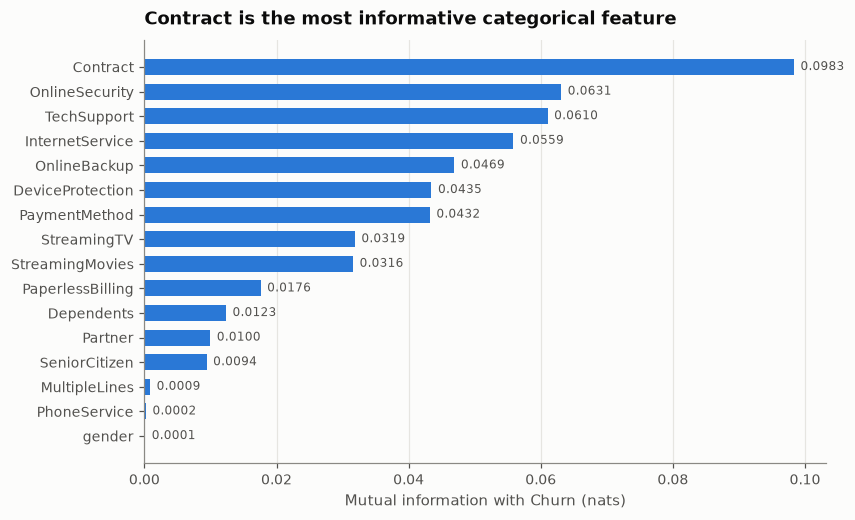

In [26]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(mi.index, mi.values, color=STAY, height=0.65)
for y, value in enumerate(mi.values):
    ax.text(value + 0.001, y, f"{value:.4f}", va="center", fontsize=8, color=INK_2)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Mutual information with Churn (nats)")
ax.set_title("Contract is the most informative categorical feature")
plt.show()

**Interpretation:** `Contract` is the most informative feature. It removes about $0.098 / 0.58 \approx 17\%$ of the uncertainty about churn on its own. `gender`, `PhoneService`, and `MultipleLines` have an MI close to $0$, which confirms the risk-ratio analysis above: they carry almost no information about churn.

## 8. Feature importance for numerical features: Correlation

### 8.1 Pearson correlation coefficient

For numerical features, we measure the **linear** relationship with the target using the **Pearson correlation coefficient**:

$$
r_{XY} = \frac{\operatorname{cov}(X, Y)}{\sigma_X\,\sigma_Y}
= \frac{\sum_{i=1}^{n}(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n}(x_i - \bar{x})^2}\;\sqrt{\sum_{i=1}^{n}(y_i - \bar{y})^2}}
$$

The numerator is large and positive when $x_i$ and $y_i$ tend to be **above their means together**. The denominator normalizes the result so that $-1 \le r \le 1$.

| Value of $r$ | Meaning in our case |
|---|---|
| $r > 0$ | Larger $X$ ⟹ **more** churn (e.g. higher monthly charges → more churn) |
| $r < 0$ | Larger $X$ ⟹ **less** churn (e.g. longer tenure → less churn) |
| $r \approx 0$ | No *linear* relationship (there may still be a non-linear one!) |
| $\lvert r\rvert$: 0.1 / 0.3 / 0.5 | Rule of thumb: weak / moderate / strong |

> 💡 When one variable is binary (like `Churn`), Pearson's $r$ is called the **point-biserial correlation**. It is directly related to the difference between the group means:
> $$r_{pb} = \frac{\bar{x}_1 - \bar{x}_0}{s_X}\sqrt{p\,(1-p)}$$
> where $\bar{x}_1, \bar{x}_0$ are the means of $X$ among churners and non-churners, $s_X$ is the standard deviation of $X$, and $p$ is the churn rate.

> ⚠️ **Correlation ≠ causation.** A correlation only says that two variables move together. It does not say that one causes the other.

In [27]:
# pandas: correlation of every numerical column with the target
correlations = df_train_full[numeric_features].corrwith(df_train_full.Churn)
correlations.to_frame("Pearson r")

,Pearson r
tenure,-0.3519
MonthlyCharges,0.1968
TotalCharges,-0.1964


**The same result in three other ways:**
1. `sklearn.feature_selection.r_regression`, which computes Pearson's $r$ between every column of $X$ and $y$,
2. the formula implemented by hand,
3. the point-biserial formula.

In [28]:
from sklearn.feature_selection import r_regression

# 1) scikit-learn (X must be 2-D: one column per feature)
r_sklearn = r_regression(df_train_full[numeric_features].values, df_train_full.Churn.values)


# 2) Pearson's formula by hand
def pearson_r(x, y):
    dx, dy = x - x.mean(), y - y.mean()
    return np.sum(dx * dy) / np.sqrt(np.sum(dx ** 2) * np.sum(dy ** 2))


r_manual = [pearson_r(df_train_full[f].values, df_train_full.Churn.values)
            for f in numeric_features]


# 3) Point-biserial formula
def point_biserial(x, y):
    p = y.mean()
    return (x[y == 1].mean() - x[y == 0].mean()) / x.std() * np.sqrt(p * (1 - p))


r_pb = [point_biserial(df_train_full[f].values, df_train_full.Churn.values)
        for f in numeric_features]

pd.DataFrame({"pandas": correlations, "r_regression": r_sklearn,
              "by hand": r_manual, "point-biserial": r_pb})

,pandas,r_regression,by hand,point-biserial
tenure,-0.3519,-0.3519,-0.3519,-0.3519
MonthlyCharges,0.1968,0.1968,0.1968,0.1968
TotalCharges,-0.1964,-0.1964,-0.1964,-0.1964


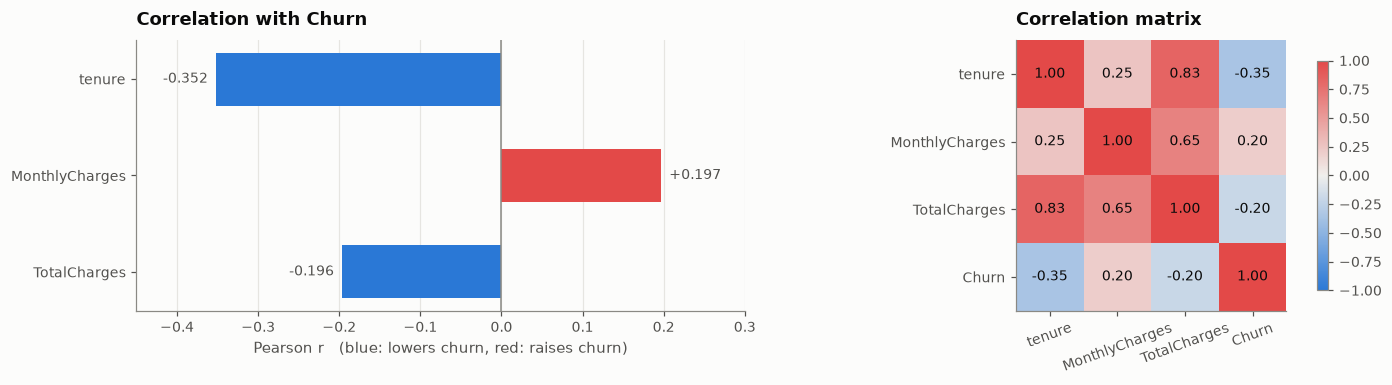

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1]})

# Left: correlation of each feature with the target
ax = axes[0]
colors = [RAISE if r > 0 else LOWER for r in correlations]
ax.barh(correlations.index, correlations.values, color=colors, height=0.55)
for y, r in enumerate(correlations.values):
    ax.text(r + (0.01 if r > 0 else -0.01), y, f"{r:+.3f}", va="center",
            ha="left" if r > 0 else "right", fontsize=9, color=INK_2)
ax.axvline(0, color=INK_3, linewidth=1)
ax.set_xlim(-0.45, 0.3)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_title("Correlation with Churn")
ax.set_xlabel("Pearson r   (blue: lowers churn, red: raises churn)")

# Right: correlations between the numerical features themselves
ax = axes[1]
corr_matrix = df_train_full[numeric_features + ["Churn"]].corr()
im = ax.imshow(corr_matrix, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix)), corr_matrix.columns, rotation=20)
ax.set_yticks(range(len(corr_matrix)), corr_matrix.columns)
for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center",
                fontsize=9, color=INK)
ax.grid(False)
ax.set_title("Correlation matrix")
fig.colorbar(im, ax=ax, shrink=0.85)
fig.tight_layout()
plt.show()

**Interpretation:**
- **`tenure`** ($r \approx -0.35$, moderate and negative): the longer someone stays, the less likely they are to leave. Loyal customers stay loyal.
- **`MonthlyCharges`** ($r \approx +0.20$, weak and positive): expensive plans go with more churn.
- **`TotalCharges`** ($r \approx -0.20$): negative, because it is strongly correlated with tenure ($r \approx 0.83$, see the matrix). Two features that carry almost the same information are called **collinear**.

Correlation summarizes the relationship in one number. Let's check it by looking at the churn rate in a few **tenure** and **monthly charge** buckets:

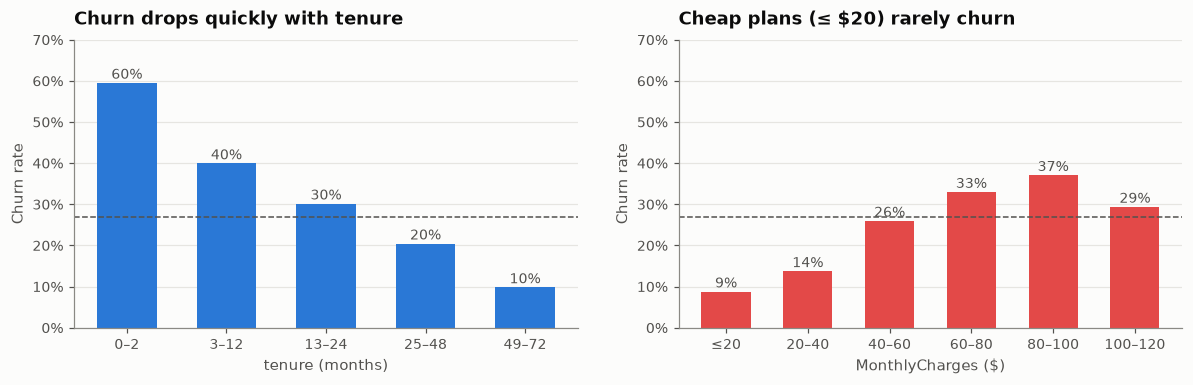

In [30]:
tenure_buckets = pd.cut(df_train_full.tenure, bins=[-1, 2, 12, 24, 48, 72],
                        labels=["0–2", "3–12", "13–24", "25–48", "49–72"])
charge_buckets = pd.cut(df_train_full.MonthlyCharges, bins=[0, 20, 40, 60, 80, 100, 120],
                        labels=["≤20", "20–40", "40–60", "60–80", "80–100", "100–120"])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, buckets, xlabel, color in [(axes[0], tenure_buckets, "tenure (months)", LOWER),
                                   (axes[1], charge_buckets, "MonthlyCharges ($)", RAISE)]:
    rates = df_train_full.groupby(buckets, observed=True).Churn.mean()
    ax.bar(rates.index.astype(str), rates.values, color=color, width=0.6)
    for x, rate in enumerate(rates.values):
        ax.text(x, rate + 0.01, f"{rate:.0%}", ha="center", fontsize=9, color=INK_2)
    ax.axhline(global_churn_rate, color=INK_2, linestyle="--", linewidth=1)
    ax.set_ylim(0, 0.7)
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Churn rate")
axes[0].set_title("Churn drops quickly with tenure")
axes[1].set_title("Cheap plans (≤ $20) rarely churn")
plt.show()

New customers (0–2 months) churn at almost **60 %**, while customers who stayed more than 4 years churn at under **10 %**. This matches the negative correlation.

The churn rate is **not perfectly linear** in `MonthlyCharges`: it rises and then flattens. Pearson's $r$ only captures the *linear* part of a relationship, so it is good practice to also plot the data.

## 9. One-hot encoding

Linear models compute a weighted sum $w_1 x_1 + w_2 x_2 + \dots$, so every input must be a **number**. How do we turn `Contract ∈ {Month-to-month, One year, Two year}` into numbers?

❌ **Bad idea: label encoding** (`0, 1, 2`). This invents an order and a distance that do not exist. The model would assume that "Two year" is *twice* "One year".

✅ **One-hot encoding:** create **one binary column per category**. Exactly one of them is `1`:

| Contract | → | `Contract=Month-to-month` | `Contract=One year` | `Contract=Two year` |
|---|---|:---:|:---:|:---:|
| Month-to-month | | 1 | 0 | 0 |
| One year | | 0 | 1 | 0 |
| Two year | | 0 | 0 | 1 |

Formally, a feature with $K$ categories $\{c_1, \dots, c_K\}$ becomes the vector $\mathbf{e}_k \in \{0,1\}^K$, where $e_{k,j} = \mathbb{1}[x = c_j]$. Numerical features are passed through unchanged.

### 9.1 Method 1: `DictVectorizer`

`DictVectorizer` takes a **list of dictionaries** (one per customer). It one-hot encodes the **string** values and keeps the **numeric** values as they are.

> 🔑 We call `fit_transform` on the **training** data only. This *learns* the list of categories. On validation and test data we call only `transform`, so all three matrices have the **same columns in the same order**.

In [31]:
from sklearn.feature_extraction import DictVectorizer

features = categorical_features + numeric_features

train_dicts = df_train[features].to_dict(orient="records")
valid_dicts = df_valid[features].to_dict(orient="records")

print("One customer as a dictionary:")
print(train_dicts[0])

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)  # learn the categories + transform
X_valid = dv.transform(valid_dicts)      # only transform (same columns!)

print(f"\nX_train: {X_train.shape},  X_valid: {X_valid.shape}")

One customer as a dictionary:
{'gender': 'Female', 'SeniorCitizen': 0, 'Partner': 'Yes', 'Dependents': 'Yes', 'PhoneService': 'Yes', 'MultipleLines': 'Yes', 'InternetService': 'Fiber optic', 'OnlineSecurity': 'Yes', 'OnlineBackup': 'Yes', 'DeviceProtection': 'Yes', 'TechSupport': 'Yes', 'StreamingTV': 'Yes', 'StreamingMovies': 'Yes', 'Contract': 'Two year', 'PaperlessBilling': 'Yes', 'PaymentMethod': 'Electronic check', 'tenure': 72, 'MonthlyCharges': 115.5, 'TotalCharges': 8425.15}

X_train: (4225, 45),  X_valid: (1409, 45)


In [32]:
# The columns created by DictVectorizer
pd.DataFrame(X_train[:5], columns=dv.get_feature_names_out()).T

,0,1,2,3,4
Contract=Month-to-month,0.00,1.00,1.00,1.00,0.0
Contract=One year,0.00,0.00,0.00,0.00,0.0
Contract=Two year,1.00,0.00,0.00,0.00,1.0
Dependents=No,0.00,1.00,1.00,0.00,1.0
Dependents=Yes,1.00,0.00,0.00,1.00,0.0
DeviceProtection=No,0.00,0.00,1.00,1.00,0.0
DeviceProtection=No internet service,0.00,0.00,0.00,0.00,1.0
DeviceProtection=Yes,1.00,1.00,0.00,0.00,0.0
InternetService=DSL,0.00,0.00,0.00,0.00,0.0
InternetService=Fiber optic,1.00,1.00,1.00,1.00,0.0


### 9.2 Method 2: `OneHotEncoder` + `ColumnTransformer`

The more common scikit-learn approach works directly on the **DataFrame**. A `ColumnTransformer` applies a different transformation to each group of columns.

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

ohe_transformer = ColumnTransformer([
    # handle_unknown="ignore": a category never seen in training becomes all zeros
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ("num", "passthrough", numeric_features),
])

X_train_ohe = ohe_transformer.fit_transform(df_train)
X_valid_ohe = ohe_transformer.transform(df_valid)

print("OneHotEncoder  :", X_train_ohe.shape)
print("DictVectorizer :", X_train.shape)

print("\nSeniorCitizen columns with OneHotEncoder:",
      [n for n in ohe_transformer.get_feature_names_out() if "Senior" in n])
print("SeniorCitizen columns with DictVectorizer:",
      [n for n in dv.get_feature_names_out() if "Senior" in n])

OneHotEncoder  : (4225, 46)
DictVectorizer : (4225, 45)

SeniorCitizen columns with OneHotEncoder: ['cat__SeniorCitizen_0', 'cat__SeniorCitizen_1']
SeniorCitizen columns with DictVectorizer: ['SeniorCitizen']


Why **46 vs 45** columns? `DictVectorizer` only one-hot encodes **strings**. `SeniorCitizen` holds the integers `0/1`, so it is kept as a single numeric column. `OneHotEncoder` encodes **every** column we give it, so it creates `SeniorCitizen_0` and `SeniorCitizen_1`. For a binary 0/1 feature, both versions carry the same information.

### 9.3 Which method is better?

| | `DictVectorizer` | `OneHotEncoder` + `ColumnTransformer` |
|---|---|---|
| **Input** | List of dicts (like JSON) | pandas DataFrame / arrays |
| **Deciding what to encode** | Automatic: strings → one-hot, numbers → as-is | Explicit: you list the columns |
| **Unseen categories** | Silently ignored | Configurable (`handle_unknown`) |
| **Extra options** | Few | `drop="first"`, `min_frequency`, `max_categories`, … |
| **Pipelines / `GridSearchCV`** | Possible | Designed for it |
| **Best for** | Quick prototypes, web services that receive JSON | Most production projects |

**Recommendation:** `DictVectorizer` is great for learning and for serving models behind an API, because a request body is already a dictionary. For larger projects, `ColumnTransformer` + `OneHotEncoder` inside a `Pipeline` is more explicit and safer. We will use `DictVectorizer` in the rest of this tutorial for simplicity, and show a full `Pipeline` in Section 10.6.

> 💡 **Dummy-variable trap:** with $K$ one-hot columns plus an intercept, the columns are linearly dependent (they always sum to 1). Unregularized linear regression has trouble with this, so `drop="first"` is sometimes used. scikit-learn's `LogisticRegression` uses L2 regularization by default, which handles this without problems.

## 10. Logistic Regression

### 10.1 From linear regression to logistic regression

**Linear regression** predicts a real number:

$$
z = b + w_1 x_1 + w_2 x_2 + \dots + w_d x_d = b + \mathbf{w}^\top \mathbf{x}, \qquad z \in (-\infty, +\infty)
$$

We need a **probability** $p \in (0, 1)$. Logistic regression passes the linear score $z$ through the **sigmoid** (logistic) function:

$$
\boxed{\;\hat{p} = P(y = 1 \mid \mathbf{x}) = \sigma(b + \mathbf{w}^\top \mathbf{x}), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}\;}
$$

**Properties of the sigmoid:**
- $\sigma(z) \in (0, 1)$ for every $z$, so the output is a valid probability.
- $\sigma(0) = 0.5$, and $\sigma(z) \to 1$ as $z \to +\infty$, $\sigma(z) \to 0$ as $z \to -\infty$.
- Symmetry: $\sigma(-z) = 1 - \sigma(z)$.
- Simple derivative: $\sigma'(z) = \sigma(z)\,(1 - \sigma(z))$.

### 10.2 Log-odds: why the model is still "linear"

The **odds** of churning are $\frac{p}{1-p}$. For example, $p = 0.8$ gives odds of $4{:}1$. If we invert the sigmoid, we get:

$$
\log\frac{p}{1-p} = b + w_1 x_1 + \dots + w_d x_d
$$

So logistic regression is a **linear model for the log-odds**. This gives a precise meaning to each weight:

> Increasing $x_j$ by $1$ (with everything else fixed) adds $w_j$ to the log-odds, which **multiplies the odds by $e^{w_j}$**.

- $w_j > 0$ ⟹ the feature **increases** the churn probability,
- $w_j < 0$ ⟹ the feature **decreases** it,
- $b$ (the bias / intercept) is the log-odds when all features are $0$.

### 10.3 Training: maximum likelihood (log loss)

Each label is a Bernoulli outcome with probability $\hat{p}_i$, so the likelihood of the data is $\prod_i \hat{p}_i^{\,y_i}(1-\hat{p}_i)^{1-y_i}$. Maximizing it is the same as minimizing the **binary cross-entropy** (log loss):

$$
\mathcal{L}(\mathbf{w}, b) = -\frac{1}{n}\sum_{i=1}^{n}\Big[\,y_i \log \hat{p}_i + (1 - y_i)\log(1 - \hat{p}_i)\Big] \;+\; \underbrace{\frac{1}{2C}\lVert\mathbf{w}\rVert^2}_{\text{L2 regularization}}
$$

The gradient has a very simple form, "error × input":

$$
\nabla_{\mathbf{w}}\mathcal{L} = \frac{1}{n}\sum_{i=1}^{n}(\hat{p}_i - y_i)\,\mathbf{x}_i \;+\; \frac{1}{C}\mathbf{w}
$$

There is no closed-form solution, so scikit-learn finds the optimum with an iterative solver (default: L-BFGS). The loss is **convex**, so the solver always finds the global minimum. The parameter $C$ (default $1.0$) controls the regularization strength: a **smaller** $C$ means **stronger** regularization.

### 10.4 Example

Suppose $b = -2.5$, $w_{\text{month-to-month}} = 1.0$, $w_{\text{tenure}} = -0.04$. For a month-to-month customer with $\text{tenure} = 5$:

$$
z = -2.5 + 1.0 \cdot 1 + (-0.04)\cdot 5 = -1.7, \qquad \hat{p} = \sigma(-1.7) = \frac{1}{1 + e^{1.7}} \approx 0.15
$$

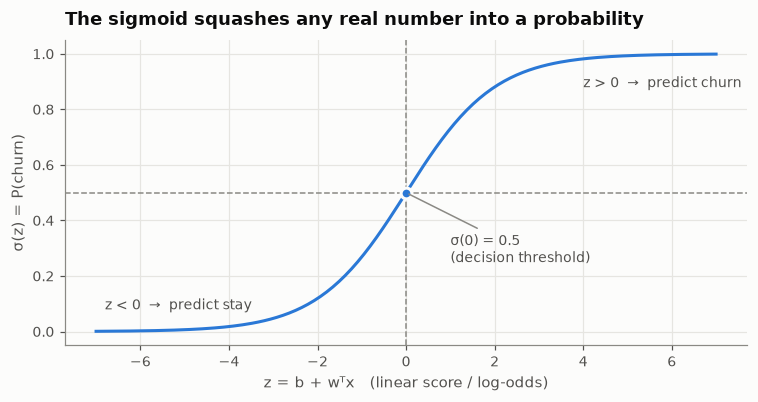

In [34]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


z = np.linspace(-7, 7, 200)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(z, sigmoid(z), color=STAY)
ax.axhline(0.5, color=INK_3, linestyle="--", linewidth=1)
ax.axvline(0, color=INK_3, linestyle="--", linewidth=1)
ax.scatter([0], [0.5], s=50, color=STAY, zorder=3, edgecolor=SURFACE, linewidth=2)
ax.annotate("σ(0) = 0.5\n(decision threshold)", xy=(0, 0.5), xytext=(1.0, 0.25),
            color=INK_2, fontsize=9, arrowprops=dict(arrowstyle="-", color=INK_3))
ax.text(4.0, 0.88, "z > 0  →  predict churn", color=INK_2, fontsize=9)
ax.text(-6.8, 0.08, "z < 0  →  predict stay", color=INK_2, fontsize=9)
ax.set_xlabel("z = b + wᵀx   (linear score / log-odds)")
ax.set_ylabel("σ(z) = P(churn)")
ax.set_title("The sigmoid squashes any real number into a probability")
plt.show()

### 10.5 Training the model

> ⚠️ **About the `ConvergenceWarning`.** If you train with a small `max_iter` (for example, `max_iter=90`), scikit-learn warns that *"lbfgs failed to converge"*. The reason is that our features have **very different scales**: one-hot columns are $0/1$, but `TotalCharges` goes up to ≈ 8,700. This makes the optimization problem badly conditioned. There are two fixes:
> 1. Increase `max_iter` (what we do here), or
> 2. **Standardize** the features (better; we do this in Section 10.6).

In [35]:
from sklearn.linear_model import LogisticRegression

print("X_train:", X_train.shape, " y_train:", y_train.shape)

model = LogisticRegression(max_iter=10_000, random_state=SEED)
model.fit(X_train, y_train)

accuracy = model.score(X_valid, y_valid)
baseline = 1 - y_valid.mean()  # always predict "stays"
print(f"\nValidation accuracy:            {accuracy:.4f}")
print(f"Baseline (always predict 0):    {baseline:.4f}")

X_train: (4225, 45)  y_train: (4225,)



Validation accuracy:            0.8034
Baseline (always predict 0):    0.7260


The model is about **80 % accurate**, compared with the **73 %** baseline. It learned something useful. Accuracy alone does not tell the whole story, though; we look at this more closely in Section 11.

#### Hard predictions vs. probabilities

- `predict_proba(X)` returns an $n \times 2$ array. Column `0` is $P(y = 0 \mid \mathbf{x})$ and column `1` is $P(y = 1 \mid \mathbf{x})$. Each row sums to 1. We care about **column 1**, the churn probability.
- `predict(X)` returns hard labels using the threshold $0.5$: $\hat{y} = \mathbb{1}[\hat{p} \ge 0.5]$.

In [36]:
proba = model.predict_proba(X_valid)
print("First 3 rows of predict_proba:\n", proba[:3].round(4))
print("Rows sum to 1:", np.allclose(proba.sum(axis=1), 1))

y_pred_proba = proba[:, 1]   # P(churn)
y_pred = model.predict(X_valid)

# predict() is exactly "probability >= 0.5"
assert np.array_equal(y_pred, (y_pred_proba >= 0.5).astype(int))

First 3 rows of predict_proba:
 [[0.9934 0.0066]
 [0.7947 0.2053]
 [0.782  0.218 ]]
Rows sum to 1: True


In [37]:
churn_customers = df_valid[y_pred == 1].customerID
print(f"{len(churn_customers)} of {len(df_valid)} validation customers are predicted to churn")
churn_customers.head()

315 of 1409 validation customers are predicted to churn


2504    8433-WXGNA
4597    3440-JPSCL
5591    7228-OMTPN
4482    6711-FLDFB
3610    2612-RANWT
Name: customerID, dtype: str

#### Opening the black box: verifying the prediction by hand

The model is just $\hat{p} = \sigma(b + \mathbf{w}^\top\mathbf{x})$. We can reproduce `predict_proba` with one line of NumPy. The model needs **one weight per input column**, so `coef_` must have the same length as the feature list:

In [38]:
w = model.coef_[0]      # shape (45,): one weight per feature column
b = model.intercept_[0] # the bias term

assert len(w) == len(dv.get_feature_names_out()) == X_train.shape[1]

manual_proba = sigmoid(X_valid @ w + b)
print("Max difference to predict_proba:", np.abs(manual_proba - y_pred_proba).max())
print(f"Intercept b = {b:.4f}  ->  sigmoid(b) = {sigmoid(b):.4f}")

Max difference to predict_proba: 0.0
Intercept b = -0.0486  ->  sigmoid(b) = 0.4879


**About the bias term:** $b$ is the log-odds of churn when **every** feature equals 0. For one-hot features this is not a realistic customer, because every real customer has exactly one category "on" per feature. So $b$ should be read as a **baseline offset** that the category weights then shift up or down, not as a probability of a real customer.

### 10.6 Interpreting the weights

Positive weights push towards churn and negative weights push towards staying. The one-hot features are all on the same $0/1$ scale, so their weights can be compared directly:

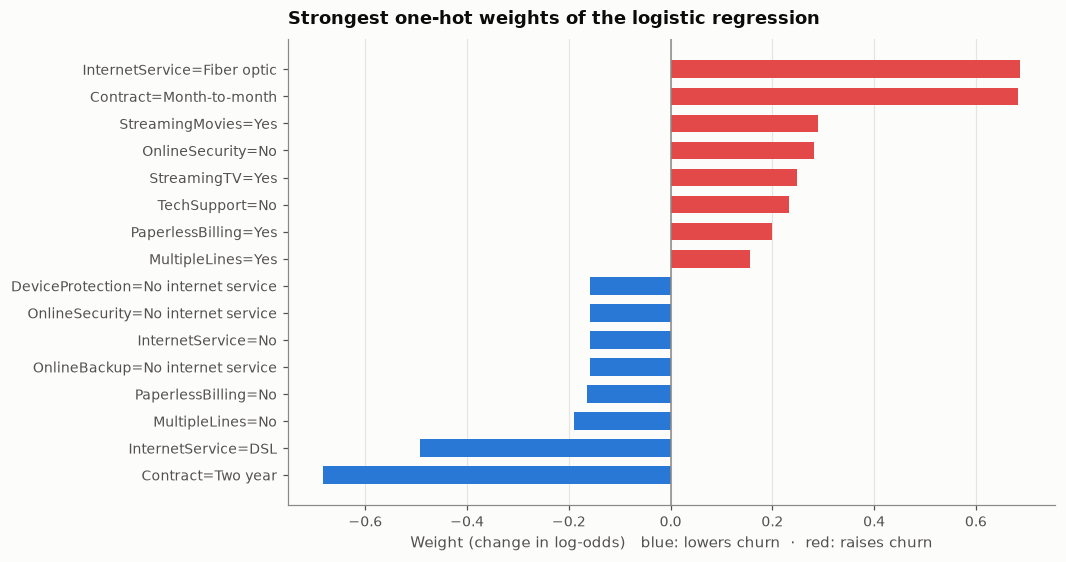

,weight
tenure,-0.0684
MonthlyCharges,-0.0173
TotalCharges,0.0004
SeniorCitizen,0.1925


In [39]:
feature_weights = pd.Series(w, index=dv.get_feature_names_out())
onehot_weights = feature_weights.drop(numeric_features + ["SeniorCitizen"]).sort_values()
top = pd.concat([onehot_weights.head(8), onehot_weights.tail(8)])

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index, top.values, color=[RAISE if v > 0 else LOWER for v in top.values], height=0.65)
ax.axvline(0, color=INK_3, linewidth=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Weight (change in log-odds)   blue: lowers churn  ·  red: raises churn")
ax.set_title("Strongest one-hot weights of the logistic regression")
plt.show()

feature_weights[numeric_features + ["SeniorCitizen"]].round(4).to_frame("weight")

The weights agree with the EDA. `InternetService=Fiber optic`, `Contract=Month-to-month`, and the *lack* of `OnlineSecurity` / `TechSupport` push towards churn. `Contract=Two year` and `InternetService=DSL` push towards staying.

> ⚠️ Read the weights **together**, not one by one. Correlated features share the "credit". For example, the weight of `Contract=Two year` is partly *absorbed* by `tenure`, because long contracts and long tenure go together.

⚠️ The numeric weights look tiny (e.g. `tenure` ≈ −0.07), but they apply **per unit**. One extra *month* is a small change, while 5 *years* of tenure is a large one. To compare features on an equal footing, we can **standardize** them first:

$$
x_j^{\text{std}} = \frac{x_j - \mu_j}{\sigma_j}
$$

After standardization, a weight means "the change in log-odds for a **one-standard-deviation** increase". As a bonus, the solver converges much faster. Here is the full, production-style `Pipeline`:

In [40]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pipeline = Pipeline([
    ("encode", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", StandardScaler(), numeric_features),
    ])),
    ("model", LogisticRegression(random_state=SEED)),  # default max_iter is enough now
])
pipeline.fit(df_train, y_train)

print(f"Validation accuracy (pipeline): {pipeline.score(df_valid, y_valid):.4f}")
print(f"Iterations needed: {pipeline['model'].n_iter_[0]}  (vs {model.n_iter_[0]} without scaling)")

std_weights = pd.Series(pipeline["model"].coef_[0],
                        index=pipeline["encode"].get_feature_names_out())
std_weights[[f"num__{f}" for f in numeric_features]].round(3).to_frame("standardized weight")

Validation accuracy (pipeline): 0.8062
Iterations needed: 28  (vs 1765 without scaling)


,standardized weight
num__tenure,-1.587
num__MonthlyCharges,0.130
num__TotalCharges,0.795


With standardized inputs, `tenure` has a weight of about $-1.6$ per standard deviation (≈ 2 years). It is the strongest single feature in the model.

Did you notice that `TotalCharges` now has a **positive** weight, even though its correlation with churn is **negative**? This is the **collinearity** from Section 8. Since $\text{TotalCharges} \approx \text{tenure} \times \text{MonthlyCharges}$, the model can use `tenure` for the "long-time customer" effect, and `TotalCharges` then only corrects for the remaining part. This is why weights of correlated features should not be read in isolation.

### 10.7 A smaller, fully interpretable model

The full model has 45 weights, which is hard to read. Let's train a **small model** with only `Contract`, `MonthlyCharges`, and `tenure`, and interpret every number.

In [41]:
small_features = ["Contract", "MonthlyCharges", "tenure"]

dv_small = DictVectorizer(sparse=False)
X_train_small = dv_small.fit_transform(df_train[small_features].to_dict(orient="records"))
X_valid_small = dv_small.transform(df_valid[small_features].to_dict(orient="records"))

model_small = LogisticRegression(max_iter=1000, random_state=SEED)
model_small.fit(X_train_small, y_train)

small_weights = pd.Series(model_small.coef_[0], index=dv_small.get_feature_names_out())
display(pd.DataFrame({"weight w": small_weights,
                      "odds multiplier exp(w)": np.exp(small_weights)}).round(3))
print(f"intercept b = {model_small.intercept_[0]:.3f}")
print(f"validation accuracy = {model_small.score(X_valid_small, y_valid):.4f}")

,weight w,odds multiplier exp(w)
Contract=Month-to-month,0.971,2.641
Contract=One year,-0.024,0.976
Contract=Two year,-0.948,0.387
MonthlyCharges,0.027,1.028
tenure,-0.036,0.964


intercept b = -2.478
validation accuracy = 0.7963


**Reading the small model** (exact numbers may differ slightly):

$$
\log\frac{p}{1-p} \approx -2.48 \;+\; \begin{cases} +0.97 & \text{month-to-month} \\ -0.02 & \text{one year} \\ -0.95 & \text{two year} \end{cases} \;+\; 0.027\cdot\text{MonthlyCharges} \;-\; 0.036\cdot\text{tenure}
$$

- **Intercept** $b \approx -2.48$: the starting log-odds before any feature is added.
- **Contract:** going from a two-year contract to month-to-month adds $\approx 0.97 - (-0.95) \approx 1.9$ to the log-odds. That **multiplies the odds of churning by $e^{1.9} \approx 6.8$**.
- **MonthlyCharges:** each extra dollar multiplies the odds by $e^{0.027} \approx 1.03$ (+3 %). Each extra **\$10** multiplies them by $e^{0.27} \approx 1.31$ (+31 %).
- **tenure:** each extra month multiplies the odds by $e^{-0.036} \approx 0.965$ (−3.5 %). Each extra **year** multiplies them by $e^{-0.43} \approx 0.65$ (−35 %).

**Worked example:** a month-to-month customer paying \$50 per month, with tenure of 4 months:

In [42]:
customer = {"Contract": "Month-to-month", "MonthlyCharges": 50, "tenure": 4}

b_small = model_small.intercept_[0]
w_small = small_weights
z = (b_small + w_small["Contract=Month-to-month"]
     + 50 * w_small["MonthlyCharges"] + 4 * w_small["tenure"])

print(f"z = {z:.3f}  ->  P(churn) = sigmoid(z) = {sigmoid(z):.3f}")
print("model.predict_proba ->", model_small.predict_proba(dv_small.transform([customer]))[0, 1].round(3))

z = -0.277  ->  P(churn) = sigmoid(z) = 0.431
model.predict_proba -> 0.431


Now let's **visualize** the small model. For a fixed monthly charge of \$70, how does the churn probability change with tenure for each contract type?

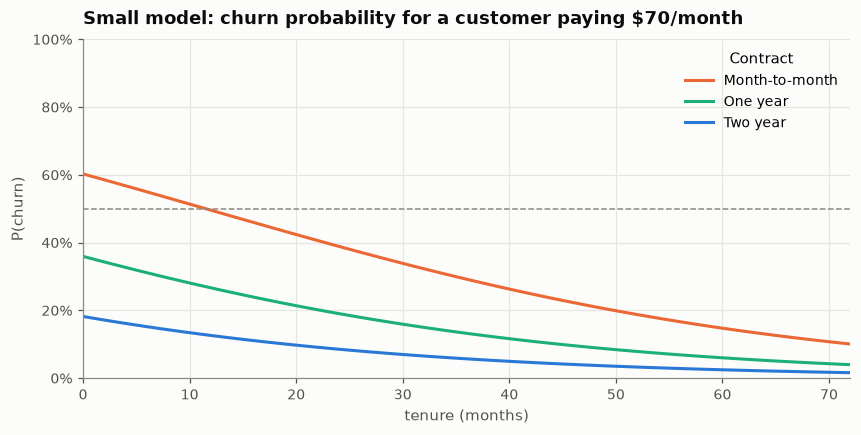

In [43]:
tenure_grid = np.arange(0, 73)

fig, ax = plt.subplots(figsize=(9, 4))
for contract, color in [("Month-to-month", CHURN), ("One year", THIRD), ("Two year", STAY)]:
    grid = [{"Contract": contract, "MonthlyCharges": 70, "tenure": t} for t in tenure_grid]
    p = model_small.predict_proba(dv_small.transform(grid))[:, 1]
    ax.plot(tenure_grid, p, color=color, label=contract)
ax.axhline(0.5, color=INK_3, linestyle="--", linewidth=1)
ax.legend(title="Contract", loc="upper right")
ax.set_xlim(0, 72)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("tenure (months)")
ax.set_ylabel("P(churn)")
ax.set_title("Small model: churn probability for a customer paying $70/month")
plt.show()

The plot shows the model's logic. **Contract type shifts the whole curve** up or down (a change in the intercept). **Tenure moves the customer along the curve.** A new month-to-month customer is very likely to churn, while a long-tenured two-year customer almost never does. Each curve is a sigmoid in tenure, but we only see the part between 0 and 72 months.

## 11. Evaluating the classifier

Accuracy alone can be **misleading** on imbalanced data. A model that never predicts churn gets 73 % accuracy and is completely useless. We need metrics that look at the **churners** specifically.

### 11.1 The confusion matrix

Every prediction falls into one of four cells:

| | Predicted: stays ($\hat{y}=0$) | Predicted: churns ($\hat{y}=1$) |
|---|---|---|
| **Actually stays** ($y=0$) | ✅ True Negative (TN) | ❌ False Positive (FP): a gift we did not need to send |
| **Actually churns** ($y=1$) | ❌ False Negative (FN): a customer we lost without trying | ✅ True Positive (TP) |

From these four numbers:

$$
\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}
\qquad
\text{Precision} = \frac{TP}{TP + FP}
\qquad
\text{Recall} = \frac{TP}{TP + FN}
\qquad
F_1 = 2\cdot\frac{\text{Precision}\cdot\text{Recall}}{\text{Precision} + \text{Recall}}
$$

- **Precision:** *"Of the customers we flagged, how many really churn?"* Low precision means we waste money on gifts.
- **Recall:** *"Of the customers who really churn, how many did we catch?"* Low recall means we lose customers.
- **$F_1$:** the harmonic mean of precision and recall. It is high only when **both** are high.

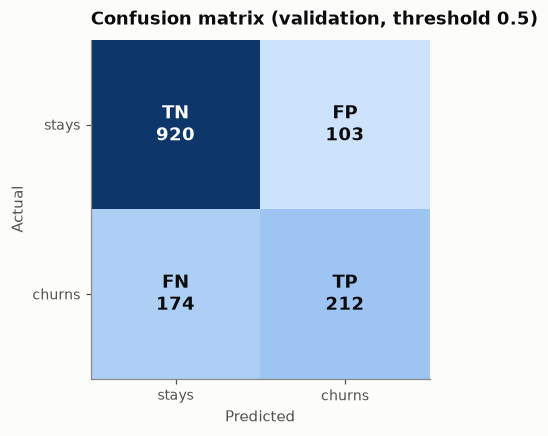

Accuracy : 0.803
Precision: 0.673   (sklearn: 0.673)
Recall   : 0.549   (sklearn: 0.549)
F1       : 0.605


In [44]:
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)

cm = confusion_matrix(y_valid, y_pred)
(tn, fp), (fn, tp) = cm

fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(cm, cmap=BLUES)
labels = [["TN", "FP"], ["FN", "TP"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{labels[i][j]}\n{cm[i, j]:,}", ha="center", va="center", fontsize=12,
                color="white" if cm[i, j] > cm.max() / 2 else INK, fontweight="bold")
ax.set_xticks([0, 1], ["stays", "churns"])
ax.set_yticks([0, 1], ["stays", "churns"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.grid(False)
ax.set_title("Confusion matrix (validation, threshold 0.5)")
plt.show()

print(f"Accuracy : {(tp + tn) / cm.sum():.3f}")
print(f"Precision: {tp / (tp + fp):.3f}   (sklearn: {precision_score(y_valid, y_pred):.3f})")
print(f"Recall   : {tp / (tp + fn):.3f}   (sklearn: {recall_score(y_valid, y_pred):.3f})")
print(f"F1       : {f1_score(y_valid, y_pred):.3f}")

The precision is reasonable: about 2 out of 3 flagged customers really churn. But the recall is only about **55 %**, which means **the model misses almost half of the churners**. For a retention campaign, that is a problem.

### 11.2 Choosing the decision threshold

The threshold 0.5 is only a default. Every threshold $t$ gives a different trade-off:

$$
\hat{y} = \mathbb{1}\big[\hat{p} \ge t\big]
$$

- Lowering $t$ flags more customers: **recall ↑**, precision ↓.
- Raising $t$ flags fewer customers: **precision ↑**, recall ↓.

The right threshold depends on **business costs**. If a gift costs \$10 and a lost customer costs \$500, missing a churner (FN) is much worse than sending an unnecessary gift (FP), so a lower threshold makes sense.

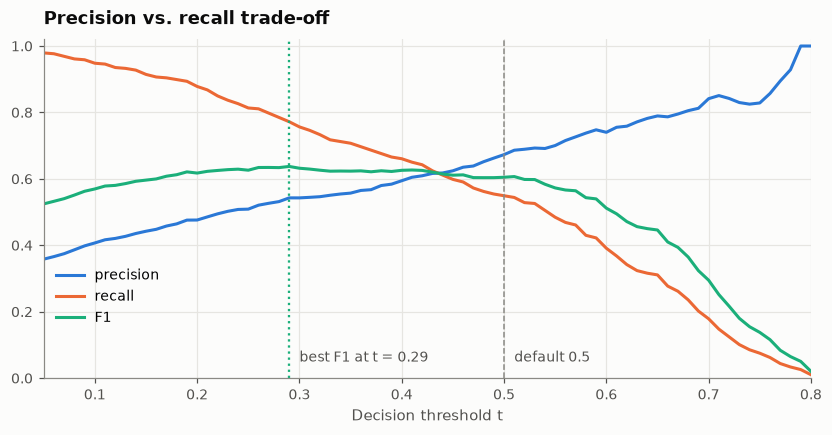

,precision,recall,F1
0.3,0.543,0.756,0.632
0.4,0.594,0.661,0.626
0.5,0.673,0.549,0.605
0.6,0.740,0.391,0.512


In [45]:
# Above ~0.8 almost no customer is flagged, so the curves are not meaningful there
thresholds = np.linspace(0.05, 0.80, 76).round(2)
scores = pd.DataFrame({
    "precision": [precision_score(y_valid, y_pred_proba >= t, zero_division=0) for t in thresholds],
    "recall": [recall_score(y_valid, y_pred_proba >= t) for t in thresholds],
    "F1": [f1_score(y_valid, y_pred_proba >= t) for t in thresholds],
}, index=thresholds)
best_t = scores.F1.idxmax()

fig, ax = plt.subplots(figsize=(9, 4))
for column, color in [("precision", STAY), ("recall", CHURN), ("F1", THIRD)]:
    ax.plot(scores.index, scores[column], color=color, label=column)
ax.axvline(0.5, color=INK_3, linestyle="--", linewidth=1)
ax.axvline(best_t, color=THIRD, linestyle=":", linewidth=1.5)
ax.text(best_t + 0.01, 0.05, f"best F1 at t = {best_t:.2f}", color=INK_2, fontsize=9)
ax.text(0.51, 0.05, "default 0.5", color=INK_2, fontsize=9)
ax.legend(loc="lower left", bbox_to_anchor=(0, 0.12))
ax.set_xlim(0.05, 0.80)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Decision threshold t")
ax.set_title("Precision vs. recall trade-off")
plt.show()

scores.loc[[0.3, 0.4, 0.5, 0.6]].round(3)

### 11.3 The ROC curve and AUC

Instead of picking one threshold, we can look at **all** thresholds at once. For each $t$, we compute:

$$
\text{TPR}(t) = \text{Recall}(t) = \frac{TP}{TP+FN}, \qquad \text{FPR}(t) = \frac{FP}{FP+TN}
$$

and plot TPR against FPR. This is the **ROC curve**. The **AUC** (area under the curve) has a nice probabilistic meaning:

$$
\text{AUC} = P\big(\hat{p}(\text{random churner}) > \hat{p}(\text{random non-churner})\big)
$$

So the AUC is the probability that the model **ranks** a random churner above a random non-churner. An AUC of $0.5$ means random guessing and $1.0$ means a perfect ranking. Unlike accuracy, the AUC does not depend on the threshold or on the class balance.

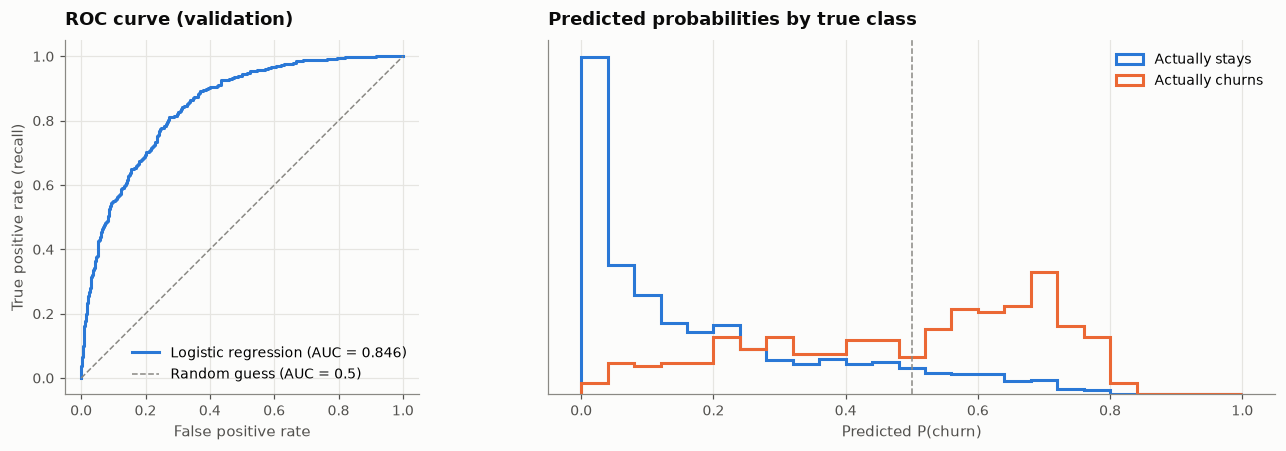

In [46]:
fpr, tpr, _ = roc_curve(y_valid, y_pred_proba)
auc = roc_auc_score(y_valid, y_pred_proba)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

ax = axes[0]
ax.plot(fpr, tpr, color=STAY, label=f"Logistic regression (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], color=INK_3, linestyle="--", linewidth=1, label="Random guess (AUC = 0.5)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curve (validation)")
ax.legend(loc="lower right")
ax.set_aspect("equal")

ax = axes[1]
bins = np.linspace(0, 1, 26)
for label, color, name in [(0, STAY, "Actually stays"), (1, CHURN, "Actually churns")]:
    ax.hist(y_pred_proba[y_valid == label], bins=bins, density=True, histtype="step",
            linewidth=2, color=color, label=name)
ax.axvline(0.5, color=INK_3, linestyle="--", linewidth=1)
ax.set_xlabel("Predicted P(churn)")
ax.set_yticks([])
ax.grid(axis="y", visible=False)
ax.set_title("Predicted probabilities by true class")
ax.legend()
fig.tight_layout()
plt.show()

The model separates the classes quite well (AUC ≈ 0.85). The right plot shows **why** the recall is limited: many real churners receive probabilities between 0.2 and 0.5, which falls below the default threshold.

## 12. Using the model

### 12.1 Training the final model

We used the validation set to make our choices. Now we **retrain on train + validation** (`df_train_full`, 80 % of the data): more data usually gives a better model. Then we evaluate **once** on the untouched test set.

> 🔑 We fit a **new** `DictVectorizer` on `df_train_full`, and only `transform` the test set with it.

In [47]:
y_train_full = df_train_full.Churn.values

dv_full = DictVectorizer(sparse=False)
X_train_full = dv_full.fit_transform(df_train_full[features].to_dict(orient="records"))

test_dicts = df_test[features].to_dict(orient="records")
X_test = dv_full.transform(test_dicts)

print("X_train_full:", X_train_full.shape, " X_test:", X_test.shape)

model_full = LogisticRegression(max_iter=10_000, random_state=SEED)
model_full.fit(X_train_full, y_train_full)

test_proba = model_full.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= 0.5).astype(int)
print(f"\nTest accuracy : {accuracy_score(y_test, test_pred):.4f}")
print(f"Test AUC      : {roc_auc_score(y_test, test_proba):.4f}")
print(f"Test recall   : {recall_score(y_test, test_pred):.4f}")
print(f"Test precision: {precision_score(y_test, test_pred):.4f}")

X_train_full: (5634, 45)  X_test: (1409, 45)



Test accuracy : 0.8119
Test AUC      : 0.8585
Test recall   : 0.5862
Test precision: 0.6277


The test results are close to the validation results, so the model **generalizes**: it did not just memorize the training data.

### 12.2 A retention campaign

Let's find the test customers who are likely to leave. Instead of a plain yes/no list, we **rank them by churn probability**. If the budget is limited, we contact the riskiest customers first.

In [48]:
campaign = (pd.DataFrame({"customerID": df_test.customerID.values,
                          "churn_probability": test_proba})
            .query("churn_probability >= 0.5")
            .sort_values("churn_probability", ascending=False)
            .reset_index(drop=True))

print(f"{len(campaign)} of {len(df_test)} test customers ({len(campaign) / len(df_test):.1%}) "
      "are predicted to churn.\n")

# We send them a gift to keep them (we don't tell them why!)
for _, row in campaign.head(5).iterrows():
    print(f"Hello dear {row.customerID}, we have a special gift for you! 🎁"
          f"   (P(churn) = {row.churn_probability:.2f})")
print("...")

325 of 1409 test customers (23.1%) are predicted to churn.

Hello dear 7024-OHCCK, we have a special gift for you! 🎁   (P(churn) = 0.84)
Hello dear 8098-LLAZX, we have a special gift for you! 🎁   (P(churn) = 0.83)
Hello dear 4910-GMJOT, we have a special gift for you! 🎁   (P(churn) = 0.82)
Hello dear 0295-PPHDO, we have a special gift for you! 🎁   (P(churn) = 0.81)
Hello dear 4826-XTSOH, we have a special gift for you! 🎁   (P(churn) = 0.81)
...


### 12.3 Scoring a single customer

In real life, the model is usually called for **one customer at a time**. For example, a web service receives the customer's data as JSON (a dictionary) and returns a churn probability. This is where `DictVectorizer` is very convenient.

In [49]:
customer = test_dicts[10]
customer

{'gender': 'Male',
 'SeniorCitizen': 1,
 'Partner': 'Yes',
 'Dependents': 'Yes',
 'PhoneService': 'Yes',
 'MultipleLines': 'No',
 'InternetService': 'Fiber optic',
 'OnlineSecurity': 'No',
 'OnlineBackup': 'Yes',
 'DeviceProtection': 'No',
 'TechSupport': 'No',
 'StreamingTV': 'Yes',
 'StreamingMovies': 'Yes',
 'Contract': 'Month-to-month',
 'PaperlessBilling': 'Yes',
 'PaymentMethod': 'Mailed check',
 'tenure': 32,
 'MonthlyCharges': 93.95,
 'TotalCharges': 2861.45}

In [50]:
# The model expects a feature matrix, not a dictionary -> transform it first.
# Note the list: transform() expects a *list* of dicts and returns a (1, 45) matrix.
customer_features = dv_full.transform([customer])
print("Shape:", customer_features.shape)

p_full = model_full.predict_proba(customer_features)[0, 1]
p_first = model.predict_proba(customer_features)[0, 1]
print(f"P(churn) final model     : {p_full:.3f}")
print(f"P(churn) first model     : {p_first:.3f}")
print(f"Actual label             : {y_test[10]}  (0 = stayed)")

Shape: (1, 45)
P(churn) final model     : 0.480
P(churn) first model     : 0.524
Actual label             : 0  (0 = stayed)


Both models were trained with `DictVectorizer`s that learned the **same 45 columns in the same (alphabetical) order**. Only because of this can we pass the same feature vector to both. In general, **always transform with the vectorizer that was fitted together with the model.**

This customer is a **borderline case**. The final model says ≈ 48 % (just below the threshold, so "stays"), but the first model says ≈ 52 % (just above, so "churns"). The customer really did stay. Small differences in the training data can flip a prediction near 0.5, which is one more reason to work with **probabilities** and not only with hard labels. Let's look at another one, the last customer in the test set:

In [51]:
customer_2 = test_dicts[-1]
customer_2_features = dv_full.transform([customer_2])

print(f"P(churn) = {model_full.predict_proba(customer_2_features)[0, 1]:.3f}")
print(f"Actual   = {y_test[-1]}  (1 = churned)")

P(churn) = 0.640
Actual   = 1  (1 = churned)


## 13. The Perceptron

### 13.1 History and model

The **perceptron** (Frank Rosenblatt, 1958) is one of the oldest learning algorithms, and it is the ancestor of today's neural networks. Like logistic regression, it computes a **linear score**. Instead of a smooth sigmoid, it uses a hard **step function**:

$$
\hat{y} = \operatorname{sign}\big(\mathbf{w}^\top \mathbf{x} + b\big) =
\begin{cases} +1 & \text{if } \mathbf{w}^\top \mathbf{x} + b > 0 \\ -1 & \text{otherwise} \end{cases}
$$

The perceptron uses labels $y \in \{-1, +1\}$ (instead of $\{0, 1\}$), because this makes the math much cleaner. Geometrically, the equation $\mathbf{w}^\top\mathbf{x} + b = 0$ describes a **hyperplane** that splits the feature space into a "churn" half and a "stay" half.

| | Logistic regression | Perceptron |
|---|---|---|
| Score | $z = \mathbf{w}^\top\mathbf{x} + b$ | $z = \mathbf{w}^\top\mathbf{x} + b$ |
| Output | $\sigma(z) \in (0,1)$, a **probability** | $\operatorname{sign}(z) \in \{-1, +1\}$, only a **label** |
| Loss | Log loss $\log(1 + e^{-yz})$ | Perceptron loss $\max(0, -yz)$ |
| Learns from | **every** example (a little) | **only mistakes** |

### 13.2 The learning rule

The quantity $y_i(\mathbf{w}^\top\mathbf{x}_i + b)$ is the **functional margin**. It is positive when example $i$ is classified correctly and $\le 0$ when it is wrong. The perceptron loops over the training data, and **whenever it makes a mistake** it updates:

$$
\text{if } y_i\,(\mathbf{w}^\top \mathbf{x}_i + b) \le 0: \qquad
\mathbf{w} \leftarrow \mathbf{w} + \eta\, y_i\, \mathbf{x}_i, \qquad
b \leftarrow b + \eta\, y_i
$$

**Why does this help?** After the update, the margin of the same example becomes:

$$
y_i\big((\mathbf{w} + \eta y_i \mathbf{x}_i)^\top\mathbf{x}_i + (b + \eta y_i)\big)
= \underbrace{y_i(\mathbf{w}^\top\mathbf{x}_i + b)}_{\text{old margin}} + \eta\,\underbrace{y_i^2}_{=1}\big(\lVert\mathbf{x}_i\rVert^2 + 1\big)
$$

So every update **increases** the margin of the misclassified point by $\eta(\lVert\mathbf{x}_i\rVert^2 + 1) > 0$. The hyperplane is pushed towards classifying that point correctly.

**The rule is gradient descent.** The perceptron loss is

$$
\mathcal{L}(\mathbf{w}, b) = \sum_{i=1}^{n} \max\big(0,\; -y_i(\mathbf{w}^\top\mathbf{x}_i + b)\big)
$$

For a misclassified point, $\nabla_{\mathbf{w}} = -y_i\mathbf{x}_i$ and $\nabla_b = -y_i$. One stochastic gradient step with learning rate $\eta$ is exactly the update above. For correctly classified points the gradient is $0$, so nothing changes.

> 💡 When we start from $\mathbf{w} = \mathbf{0}$, the learning rate $\eta$ does **not** change the predictions. Every weight is then a sum of $\eta \cdot (\pm\mathbf{x}_i)$ terms, so $\eta$ only rescales $\mathbf{w}$ and $b$, and $\operatorname{sign}(\cdot)$ ignores the scale. We use $\eta = 1$.

### 13.3 Convergence and the averaged perceptron

**Perceptron convergence theorem (Novikoff, 1962).** Suppose the data is **linearly separable**: some unit vector $\mathbf{w}^*$ classifies every point with margin $\gamma > 0$, and $\lVert\mathbf{x}_i\rVert \le R$ for all $i$. Then the perceptron makes at most

$$
\left(\frac{R}{\gamma}\right)^2 \text{ mistakes}
$$

and then stops changing.

⚠️ **Real data is almost never linearly separable**, and churn data certainly is not: two customers with identical features can make different decisions. In that case the perceptron **never converges**. The weights keep jumping around, and the final $\mathbf{w}$ depends on whichever example happened to come last.

✅ **Fix: the averaged perceptron** (Freund & Schapire, 1999). Instead of the last weight vector, we use the **average of all intermediate weight vectors**:

$$
\bar{\mathbf{w}} = \frac{1}{T}\sum_{t=1}^{T}\mathbf{w}_t, \qquad \bar{b} = \frac{1}{T}\sum_{t=1}^{T} b_t
$$

where $T$ is the total number of steps. Weight vectors that "survived" many steps without a mistake get more weight in the average. This makes the result much more **stable** and usually more accurate.

### 13.4 Visualizing the three loss functions

Write $m = y \cdot z$ for the margin. All three losses below are functions of $m$:

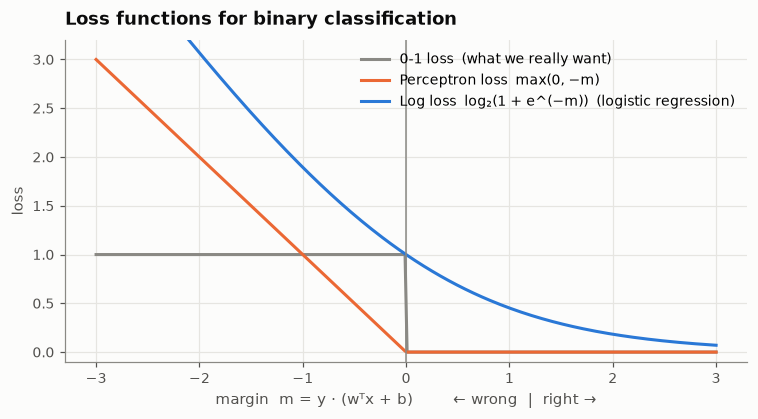

In [52]:
margin = np.linspace(-3, 3, 300)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(margin, (margin <= 0).astype(float), color=INK_3, label="0-1 loss  (what we really want)")
ax.plot(margin, np.maximum(0, -margin), color=CHURN, label="Perceptron loss  max(0, −m)")
ax.plot(margin, np.log1p(np.exp(-margin)) / np.log(2), color=STAY,
        label="Log loss  log₂(1 + e^(−m))  (logistic regression)")
ax.axvline(0, color=INK_3, linewidth=1)
ax.set_ylim(-0.1, 3.2)
ax.set_xlabel("margin  m = y · (wᵀx + b)        ← wrong  |  right →")
ax.set_ylabel("loss")
ax.set_title("Loss functions for binary classification")
ax.legend(loc="upper right")
plt.show()

- The **0-1 loss** counts errors, but it is flat everywhere, so it gives no gradient to follow.
- The **perceptron loss** is $0$ as soon as a point is on the correct side (even if only barely). It does not care *how confident* the model is.
- The **log loss** keeps pushing correct points to larger margins. This is why logistic regression gives better-calibrated scores that can be read as probabilities.

### 13.5 Feature scaling (essential!)

The update $\mathbf{w} \leftarrow \mathbf{w} + y_i\mathbf{x}_i$ adds the **raw feature values**. Without scaling, `TotalCharges` (up to ≈ 8,700) would completely dominate the one-hot features ($0/1$). We **standardize** each feature using the mean and standard deviation of the **training set**:

$$
x_j \leftarrow \frac{x_j - \mu_j^{\text{train}}}{\sigma_j^{\text{train}}}
$$

In [53]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)  # learn mu and sigma on train only
X_valid_s = scaler.transform(X_valid)      # reuse them for validation

print("Before scaling, column ranges:", X_train.min(axis=0).min(), "...", X_train.max(axis=0).max())
print("After scaling, means ≈ 0:", np.allclose(X_train_s.mean(axis=0), 0, atol=1e-9),
      "| stds ≈ 1:", np.allclose(X_train_s.std(axis=0), 1))

Before scaling, column ranges: 0.0 ... 8684.8
After scaling, means ≈ 0: True | stds ≈ 1: True


### 13.6 Implementing the perceptron from scratch

The implementation follows the math above line by line. It supports both the **vanilla** and the **averaged** variant, and records the training history so we can plot it.

In [54]:
class PerceptronScratch:
    """Rosenblatt's perceptron (optionally averaged), trained with the classic mistake-driven rule.

    Labels are given as {0, 1} (like scikit-learn) and converted to {-1, +1} internally.
    """

    def __init__(self, n_epochs=20, learning_rate=1.0, average=False, random_state=None):
        self.n_epochs = n_epochs
        self.learning_rate = learning_rate
        self.average = average
        self.random_state = random_state

    def fit(self, X, y, X_val=None, y_val=None):
        rng = np.random.default_rng(self.random_state)
        n_samples, n_features = X.shape
        y_pm = np.where(y == 1, 1, -1)  # {0, 1} -> {-1, +1}

        w, b = np.zeros(n_features), 0.0           # current weights
        w_sum, b_sum, steps = np.zeros(n_features), 0.0, 0  # running sums for averaging
        self.history_ = []

        for epoch in range(self.n_epochs):
            mistakes = 0
            for i in rng.permutation(n_samples):   # shuffle every epoch
                if y_pm[i] * (X[i] @ w + b) <= 0:  # misclassified (margin <= 0)
                    w += self.learning_rate * y_pm[i] * X[i]
                    b += self.learning_rate * y_pm[i]
                    mistakes += 1
                w_sum += w
                b_sum += b
                steps += 1

            # Store the parameters the model would use if training stopped now
            if self.average:
                self.coef_, self.intercept_ = w_sum / steps, b_sum / steps
            else:
                self.coef_, self.intercept_ = w.copy(), b

            record = {"epoch": epoch + 1, "mistakes": mistakes}
            if X_val is not None:
                record["val_accuracy"] = accuracy_score(y_val, self.predict(X_val))
            self.history_.append(record)

        self.history_ = pd.DataFrame(self.history_).set_index("epoch")
        return self

    def decision_function(self, X):
        """The linear score z = Xw + b (its sign is the prediction)."""
        return X @ self.coef_ + self.intercept_

    def predict(self, X):
        return (self.decision_function(X) > 0).astype(int)

In [55]:
N_EPOCHS = 30

perceptron_vanilla = PerceptronScratch(n_epochs=N_EPOCHS, random_state=SEED)
perceptron_vanilla.fit(X_train_s, y_train, X_valid_s, y_valid)

perceptron_avg = PerceptronScratch(n_epochs=N_EPOCHS, average=True, random_state=SEED)
perceptron_avg.fit(X_train_s, y_train, X_valid_s, y_valid)

pd.DataFrame({
    "mistakes / epoch": perceptron_vanilla.history_.mistakes,
    "val acc (vanilla)": perceptron_vanilla.history_.val_accuracy,
    "val acc (averaged)": perceptron_avg.history_.val_accuracy,
}).iloc[[0, 1, 2, 4, 9, 19, 29]].round(3)

,mistakes / epoch,val acc (vanilla),val acc (averaged)
epoch,,,
1,1213,0.781,0.808
2,1182,0.753,0.809
3,1146,0.738,0.805
5,1179,0.674,0.806
10,1152,0.750,0.807
20,1186,0.660,0.809
30,1184,0.722,0.808


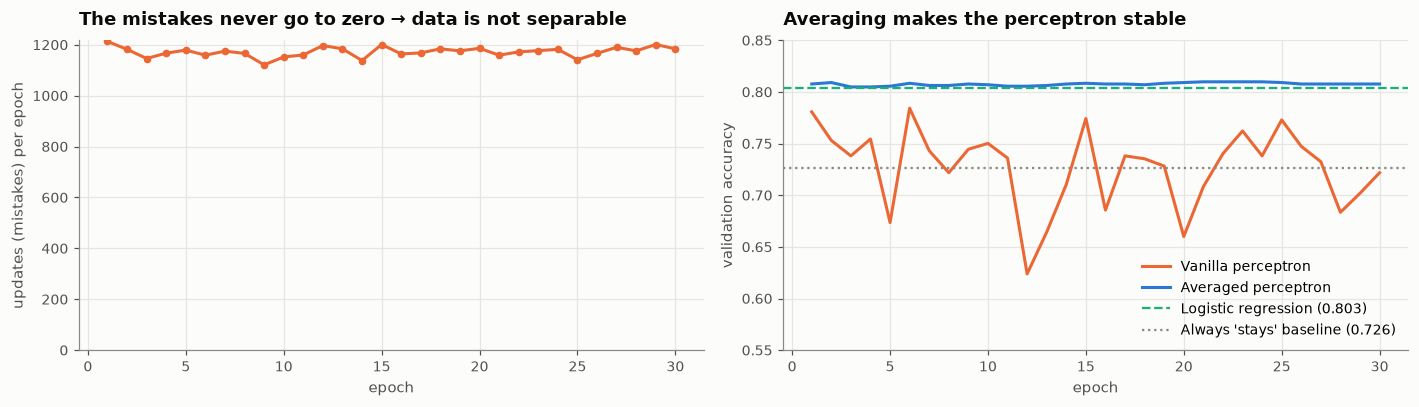

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))

ax = axes[0]
ax.plot(perceptron_vanilla.history_.index, perceptron_vanilla.history_.mistakes, color=CHURN,
        marker="o", markersize=4)
ax.set_ylim(0, None)
ax.set_xlabel("epoch")
ax.set_ylabel("updates (mistakes) per epoch")
ax.set_title("The mistakes never go to zero → data is not separable")

ax = axes[1]
for model_, color, name in [(perceptron_vanilla, CHURN, "Vanilla perceptron"),
                            (perceptron_avg, STAY, "Averaged perceptron")]:
    ax.plot(model_.history_.index, model_.history_.val_accuracy, color=color, label=name)
ax.axhline(accuracy, color=THIRD, linestyle="--", linewidth=1.5,
           label=f"Logistic regression ({accuracy:.3f})")
ax.axhline(baseline, color=INK_3, linestyle=":", linewidth=1.5,
           label=f"Always 'stays' baseline ({baseline:.3f})")
ax.set_ylim(0.55, 0.85)
ax.set_xlabel("epoch")
ax.set_ylabel("validation accuracy")
ax.set_title("Averaging makes the perceptron stable")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

**What we see:**
- The **number of mistakes per epoch never approaches zero**. This is the non-separable case described in Section 13.3, so the algorithm never converges.
- The **vanilla perceptron's** validation accuracy **jumps around** from epoch to epoch. Its final weights depend on the last few updates, so stopping at a different epoch gives a different model.
- The **averaged perceptron** is **stable** and reaches about the same accuracy as logistic regression.

### 13.7 Seeing it in 2-D

To build intuition, let's train both models on only **two** standardized features (`tenure` and `MonthlyCharges`) and draw their decision boundaries $w_1 x_1 + w_2 x_2 + b = 0$:

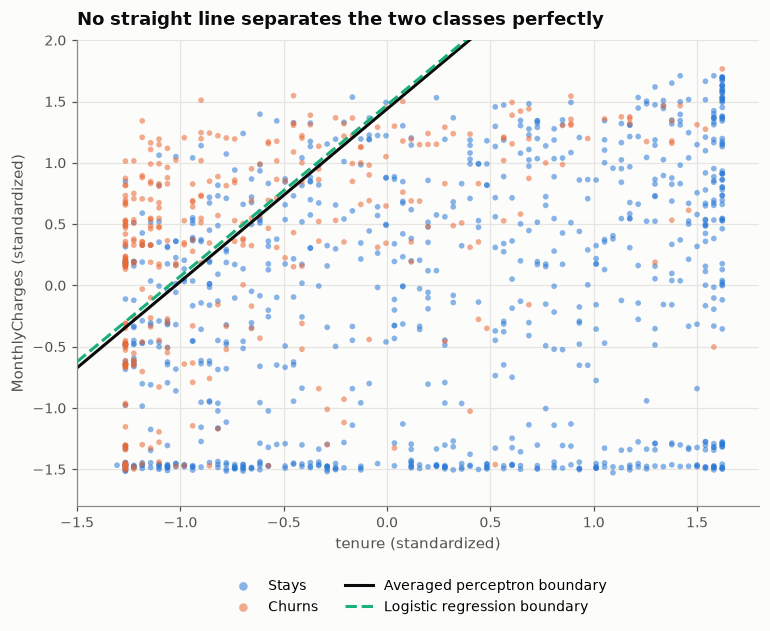

In [57]:
two_features = ["tenure", "MonthlyCharges"]
scaler_2d = StandardScaler()
X2_train = scaler_2d.fit_transform(df_train[two_features].values)

p2d = PerceptronScratch(n_epochs=N_EPOCHS, average=True, random_state=SEED).fit(X2_train, y_train)
lr2d = LogisticRegression(random_state=SEED).fit(X2_train, y_train)

rng = np.random.default_rng(SEED)
sample = rng.choice(len(X2_train), size=1200, replace=False)

fig, ax = plt.subplots(figsize=(8, 5.5))
for label, color, name in [(0, STAY, "Stays"), (1, CHURN, "Churns")]:
    mask = y_train[sample] == label
    ax.scatter(X2_train[sample][mask, 0], X2_train[sample][mask, 1], s=14, alpha=0.55,
               color=color, edgecolor="none", label=name)

x_line = np.linspace(-1.5, 1.8, 50)
for (w_, b_), color, style, name in [
        ((p2d.coef_, p2d.intercept_), INK, "-", "Averaged perceptron boundary"),
        ((lr2d.coef_[0], lr2d.intercept_[0]), THIRD, "--", "Logistic regression boundary")]:
    ax.plot(x_line, -(w_[0] * x_line + b_) / w_[1], color=color, linestyle=style, label=name)

ax.set_xlim(-1.5, 1.8)
ax.set_ylim(-1.8, 2.0)
ax.set_xlabel("tenure (standardized)")
ax.set_ylabel("MonthlyCharges (standardized)")
ax.set_title("No straight line separates the two classes perfectly")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncols=2, markerscale=1.5)
plt.show()

Churners (orange) concentrate on the **left** (short tenure), especially in the **upper left** (short tenure and high monthly charges). Both models put a linear boundary in about the same place. Orange and blue points still overlap on both sides of the line, though, so **no** linear model can classify everything correctly. This is exactly why the vanilla perceptron never stops updating.

### 13.8 Perceptron with scikit-learn

scikit-learn has a `Perceptron` class. Internally it is an `SGDClassifier` with `loss="perceptron"`, `learning_rate="constant"`, `eta0=1`, and `penalty=None`. It returns the **last** weights (it does not average), and it stops early when the training loss stops improving.

In [58]:
from sklearn.linear_model import Perceptron

sk_perceptron = Perceptron(max_iter=1000, random_state=SEED)
sk_perceptron.fit(X_train_s, y_train)

print(f"sklearn Perceptron: stopped after {sk_perceptron.n_iter_} epochs")
print(f"Validation accuracy: {sk_perceptron.score(X_valid_s, y_valid):.4f}")

sklearn Perceptron: stopped after 8 epochs
Validation accuracy: 0.7672


### 13.9 Comparing the models on the validation set

The perceptron does **not** output probabilities. Its `decision_function` (the score $z$) can still be used to **rank** customers, so we can compute an ROC curve and AUC for it as well.

In [59]:
def evaluate(y_true, y_hat, score):
    return {"accuracy": accuracy_score(y_true, y_hat),
            # zero_division=0: a model that never predicts churn gets precision 0
            "precision": precision_score(y_true, y_hat, zero_division=0),
            "recall": recall_score(y_true, y_hat),
            "F1": f1_score(y_true, y_hat),
            "AUC": roc_auc_score(y_true, score)}


valid_scores = {
    "Logistic regression": (y_pred, y_pred_proba),
    "Perceptron (scratch, vanilla)": (perceptron_vanilla.predict(X_valid_s),
                                      perceptron_vanilla.decision_function(X_valid_s)),
    "Perceptron (scratch, averaged)": (perceptron_avg.predict(X_valid_s),
                                       perceptron_avg.decision_function(X_valid_s)),
    "Perceptron (scikit-learn)": (sk_perceptron.predict(X_valid_s),
                                  sk_perceptron.decision_function(X_valid_s)),
}

comparison = pd.DataFrame({name: evaluate(y_valid, y_hat, score)
                           for name, (y_hat, score) in valid_scores.items()}).T
comparison.round(3)

,accuracy,precision,recall,F1,AUC
Logistic regression,0.803,0.673,0.549,0.605,0.846
"Perceptron (scratch, vanilla)",0.722,0.494,0.648,0.561,0.780
"Perceptron (scratch, averaged)",0.808,0.689,0.544,0.608,0.848
Perceptron (scikit-learn),0.767,0.582,0.531,0.556,0.802


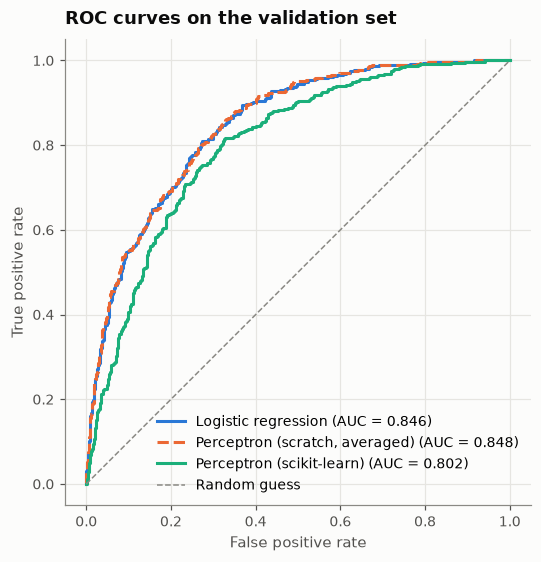

In [60]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for (name, (_, score)), color, style in zip(
        [(k, v) for k, v in valid_scores.items() if "vanilla" not in k],
        [STAY, CHURN, THIRD], ["-", "--", "-"]):
    fpr_, tpr_, _ = roc_curve(y_valid, score)
    ax.plot(fpr_, tpr_, color=color, linestyle=style,
            label=f"{name} (AUC = {roc_auc_score(y_valid, score):.3f})")
ax.plot([0, 1], [0, 1], color=INK_3, linestyle="--", linewidth=1, label="Random guess")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on the validation set")
ax.legend(loc="lower right")
ax.set_aspect("equal")
plt.show()

**Observations:**
- The **averaged perceptron** matches logistic regression almost exactly. Its ROC curve (dashed) lies on top of the logistic-regression curve. Both models learn a very similar hyperplane.
- The **vanilla perceptron** and scikit-learn's `Perceptron` (which also returns the last, non-averaged weights) are clearly worse and less stable.
- Only logistic regression gives **probabilities**. The perceptron's score $z$ ranks customers well (a good AUC), but $z = 2.3$ cannot be read as "a 90 % chance of churning".

## 14. Final comparison and conclusions

As a last step, we retrain the best perceptron (the averaged one) on **train + validation** and compare it with the final logistic regression on the **test set**, which we have not used for any decision so far.

In [61]:
scaler_full = StandardScaler()
X_train_full_s = scaler_full.fit_transform(X_train_full)
X_test_s = scaler_full.transform(X_test)

perceptron_final = PerceptronScratch(n_epochs=N_EPOCHS, average=True, random_state=SEED)
perceptron_final.fit(X_train_full_s, y_train_full)

test_results = pd.DataFrame({
    "Baseline (always 'stays')": evaluate(y_test, np.zeros_like(y_test), np.zeros(len(y_test))),
    "Logistic regression": evaluate(y_test, test_pred, test_proba),
    "Averaged perceptron": evaluate(y_test, perceptron_final.predict(X_test_s),
                                    perceptron_final.decision_function(X_test_s)),
}).T
test_results.round(3)

,accuracy,precision,recall,F1,AUC
Baseline (always 'stays'),0.753,0.000,0.000,0.000,0.500
Logistic regression,0.812,0.628,0.586,0.606,0.858
Averaged perceptron,0.810,0.622,0.586,0.604,0.858


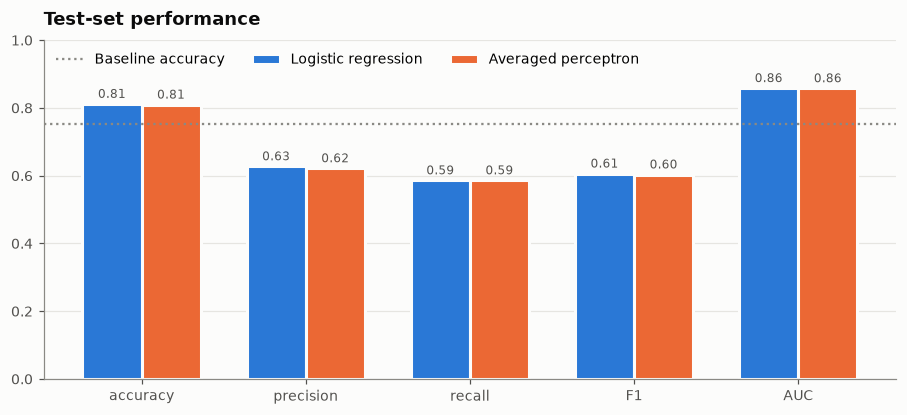

In [62]:
plot_results = test_results.drop(index="Baseline (always 'stays')")
metrics = plot_results.columns
x = np.arange(len(metrics))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 4))
for k, (name, color) in enumerate(zip(plot_results.index, [STAY, CHURN])):
    bars = ax.bar(x + (k - 0.5) * width, plot_results.loc[name], width=width, color=color,
                  edgecolor=SURFACE, linewidth=2, label=name)
    ax.bar_label(bars, fmt="%.2f", fontsize=8, color=INK_2, padding=2)
ax.axhline(test_results.loc["Baseline (always 'stays')", "accuracy"], color=INK_3,
           linestyle=":", linewidth=1.5, label="Baseline accuracy")
ax.set_xticks(x, metrics)
ax.set_ylim(0, 1)
ax.grid(axis="x", visible=False)
ax.set_title("Test-set performance")
ax.legend(loc="upper left", ncols=3)
plt.show()

### Takeaways

1. **Understand the data first.** EDA, risk ratios, mutual information, and correlation all pointed to the same drivers: **contract type, tenure, internet service type, payment method, and missing support/security add-ons**. The trained models confirmed them.
2. **Logistic regression** is a strong, fast, and **interpretable** baseline. Each weight has a clear meaning in terms of log-odds, and the model outputs **probabilities**, which we can rank and threshold to match business costs.
3. **Accuracy is not enough** for imbalanced problems. Precision, recall, F1, and AUC tell a much more useful story. Moving the threshold below 0.5 catches many more churners.
4. **The perceptron** learns the same kind of linear boundary, but:
   - it gives **no probabilities**, only labels (and an uncalibrated score),
   - it **does not converge** on non-separable data like ours, so the **averaged** version is needed for stable results,
   - it needs **feature scaling**.

   Once averaged, it performs close to logistic regression. In practice, logistic regression is usually preferred because of its probabilistic output.

### Ideas for further work

- Tune the regularization strength `C` with cross-validation (`GridSearchCV`).
- Choose the threshold from a **cost matrix** (gift cost vs. customer lifetime value).
- Try non-linear models: decision trees, random forests, gradient boosting (XGBoost / LightGBM).
- Engineer features, e.g. tenure buckets or the number of add-on services.
- Use `stratify=` in the split and **k-fold cross-validation** for more reliable estimates.
- Turn the multi-layer idea of the perceptron into a small **neural network** (`MLPClassifier`).

---

*If you found this tutorial useful, consider giving the repository a ⭐!*